# Pipeline Responsible AI — Link Prediction sur Pokec

**Objectif** : Construire un pipeline complet de Responsible AI sur un graphe social (Pokec, région Ceska republika), en suivant une approche scientifique en 4 actes :

> **Observer** → **Diagnostiquer** → **Corriger** → **Valider**

**Tâche** : Prédiction de liens (link prediction) — prédire si deux utilisateurs sont amis à partir de leurs attributs et de la structure du graphe.

**Attribut sensible** : Genre (0=F, 1=H). Le graphe présente une forte hétérophilie de genre (ratio H→F / H→H = 4.59x).

**Architecture** : GCN Encoder (2 couches, 128→64) + Décodeur dot-product + sigmoïde.

---

| Acte | Question | Méthode |
|------|----------|---------|
| 1 | Le modèle est-il biaisé ? | Baseline + métriques fairness |
| 2 | D'où vient le biais ? | GNNExplainer + ablation |
| 3 | Comment le corriger ? | Reweighting, DP reg., FairGNN |
| 4 | La correction tient-elle ? | MC Dropout, perturbations, ECE |

## 0. Configuration et chargement des données

In [1]:
import warnings; warnings.filterwarnings('ignore')
import sys, os
import gc
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import torch
from torch_geometric.transforms import RandomLinkSplit
from copy import deepcopy

# Modules du projet
from utils import *
from models import *
from metrics import *
from visualisation import *

# Ajouter le dossier notebooks/ au path Python
_nb_dir = Path(__file__).parent if '__file__' in dir() else Path('notebooks')
if not _nb_dir.exists():
    _nb_dir = Path('.')
if str(_nb_dir.resolve()) not in sys.path:
    sys.path.insert(0, str(_nb_dir.resolve()))
# Forcer le répertoire de travail dans notebooks/
if _nb_dir.resolve() != Path.cwd():
    os.chdir(_nb_dir.resolve())

# activer le rechargement automatique des modules
%load_ext autoreload
%autoreload 2

# Configuration globale
set_seed(42)
set_academic_style()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA_DIR = '../data' if Path('../data').exists() else 'data'
print(f"Device : {device} | Données : {DATA_DIR}")

# region : None pour tout le dataset (pas de split régional)
REGION='ceska republika'

Device : cuda | Données : ../data


A exécuter si besoin de vérifier la mémoire GPU disponible !

In [2]:
# Si besoin 
print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
print(torch.cuda.memory_reserved() / 1e9, "GB reserved")

0.0 GB allocated
0.0 GB reserved


A exécuter si besoin de libérer la mémoire GPU.

In [3]:
# Si besoin de libérer de la mémoire GPU
gc.collect()
torch.cuda.empty_cache()

print(torch.cuda.memory_allocated() / 1e9, "GB allocated")
print(torch.cuda.memory_reserved() / 1e9, "GB reserved")

0.0 GB allocated
0.0 GB reserved


In [4]:
# télécharger les données si elles n'existent pas déjà
print("Téléchargement des données Pokec...")
download_pokec(DATA_DIR)

Téléchargement des données Pokec...
soc-pokec-relationships.txt.gz déjà présent, skipping download.
soc-pokec-profiles.txt.gz déjà présent, skipping download.


In [5]:
# Chargement du graphe Pokec — sous-ensemble Ceska republika (région la plus biaisée)
data, sens, profiles = load_pokec(DATA_DIR, region=REGION)
print(f"Graphe : {data.num_nodes:,} noeuds | {data.edge_index.shape[1]:,} arêtes | {data.x.shape[1]} features")
print(f"Genre  : F={(sens==0).sum().item():,} | H={(sens==1).sum().item():,} | ratio H/F={(sens==1).sum()/(sens==0).sum():.2f}")

Graphe : 31,298 noeuds | 107,802 arêtes | 64 features
Genre  : F=17,835 | H=13,463 | ratio H/F=0.75


In [6]:
# Split des arêtes : Train 70% / Val 15% / Test 15%
# Le GCN ne voit QUE les arêtes train dans edge_index (pas de fuite de données)
set_seed(42)
train_data, val_data, test_data = RandomLinkSplit(
    num_val=0.15, num_test=0.15, is_undirected=True, add_negative_train_samples=True
)(data)
print(f"Train : {train_data.edge_label.shape[0]:,} paires")
print(f"Val   : {val_data.edge_label.shape[0]:,} paires")
print(f"Test  : {test_data.edge_label.shape[0]:,} paires")

Train : 75,462 paires
Val   : 16,170 paires
Test  : 16,170 paires


---

## 1 - Acte 1 — Baseline : le modèle est-il biaisé ?

On entraîne 3 architectures GNN (GCN, SGC, GAT) avec les **mêmes hyperparamètres** et on mesure performance + fairness pour identifier le modèle de référence.

| Hyperparamètre | Valeur |
|---|---|
| Hidden dim | 128 → 64 |
| Dropout | 0.5 |
| Epochs | 100 |
| Learning rate | 0.01 (GCN, SGC) / 0.005 (GAT) |
| Weight decay | 5e-4 |
| Seed | 42 |

#### 1.1 - Entraînement des 3 modèles

In [7]:
# Entraînement des 3 modèles
set_seed(42)
model_gcn = GCN(data.x.shape[1]).to(device)
best_auc_gcn = train_with_best(model_gcn, train_data, val_data, device, epochs=100, lr=0.01)
print(f"GCN — Best Val AUC : {best_auc_gcn:.4f}")

set_seed(42)
model_sgc = SGC(data.x.shape[1]).to(device)
best_auc_sgc = train_with_best(model_sgc, train_data, val_data, device, epochs=100, lr=0.01)
print(f"SGC — Best Val AUC : {best_auc_sgc:.4f}")

set_seed(42)
model_gat = GAT(data.x.shape[1], hid=128, out=64, heads=4, drop=0.5).to(device)
best_auc_gat = train_with_best(model_gat, train_data, val_data, device, epochs=100, lr=0.005)
print(f"GAT — Best Val AUC : {best_auc_gat:.4f}")

Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

GCN — Best Val AUC : 0.8328


Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

SGC — Best Val AUC : 0.7665


Entraînement:   0%|          | 0/100 [00:00<?, ?it/s]

GAT — Best Val AUC : 0.8322


#### 1.2 - Évaluation : performance + fairness + leakage

In [8]:
# Évaluation systématique : performance + fairness + leakage
results = {}
for name, mdl in [('GCN', model_gcn), ('SGC', model_sgc), ('GAT', model_gat)]:
    tp, tl, tpt, auc, ap, f, f1_global = evaluate_link_pred(mdl, test_data, sens, device)
    mdl.eval()
    with torch.no_grad():
        z = mdl.encode(test_data.x.to(device), test_data.edge_index.to(device)).cpu()
    cos_fh, gen_acc_tr, gen_acc_te, prop_majo = probe_gender(z, sens)
    data_v, pred_v, diffs = pair_distribution(tp, tl, tpt)
    results[name] = {
        'tp': tp, 'tl': tl, 'tpt': tpt,
        'auc': auc, 'ap': ap, 'f': f, 'f1': f1_global,
        'cos_fh': cos_fh, 'acc_tr': gen_acc_tr, 'acc_te': gen_acc_te,
        'prop_majo': prop_majo, 'leakage': gen_acc_te - prop_majo,
        'data_v': data_v, 'pred_v': pred_v, 'diffs': diffs,
    }

In [9]:
# Tableau comparatif des 3 modèles
pd.DataFrame({name: {
    'AUC': r['auc'], 'AP': r['ap'], 'F1': r['f1'],
    'DP gap': r['f']['DP'], 'EOpp': r['f']['EOpp'], 'EO': r['f']['EO'],
    'DI': r['f']['DI'], 'Cosine F/H': r['cos_fh'],
    'Leakage': f"{100*r['leakage']:+.1f} pp",
} for name, r in results.items()}).T

,AUC,AP,F1,DP gap,EOpp,EO,DI,Cosine F/H,Leakage
GCN,0.855595,0.872548,0.746819,0.050887,0.020536,0.049046,0.930905,0.665186,+25.1 pp
SGC,0.771399,0.719737,0.735372,0.011607,0.062678,0.124149,0.983426,-0.177934,+30.4 pp
GAT,0.848348,0.856718,0.748135,0.050016,0.018061,0.052523,0.931639,0.97247,+20.9 pp


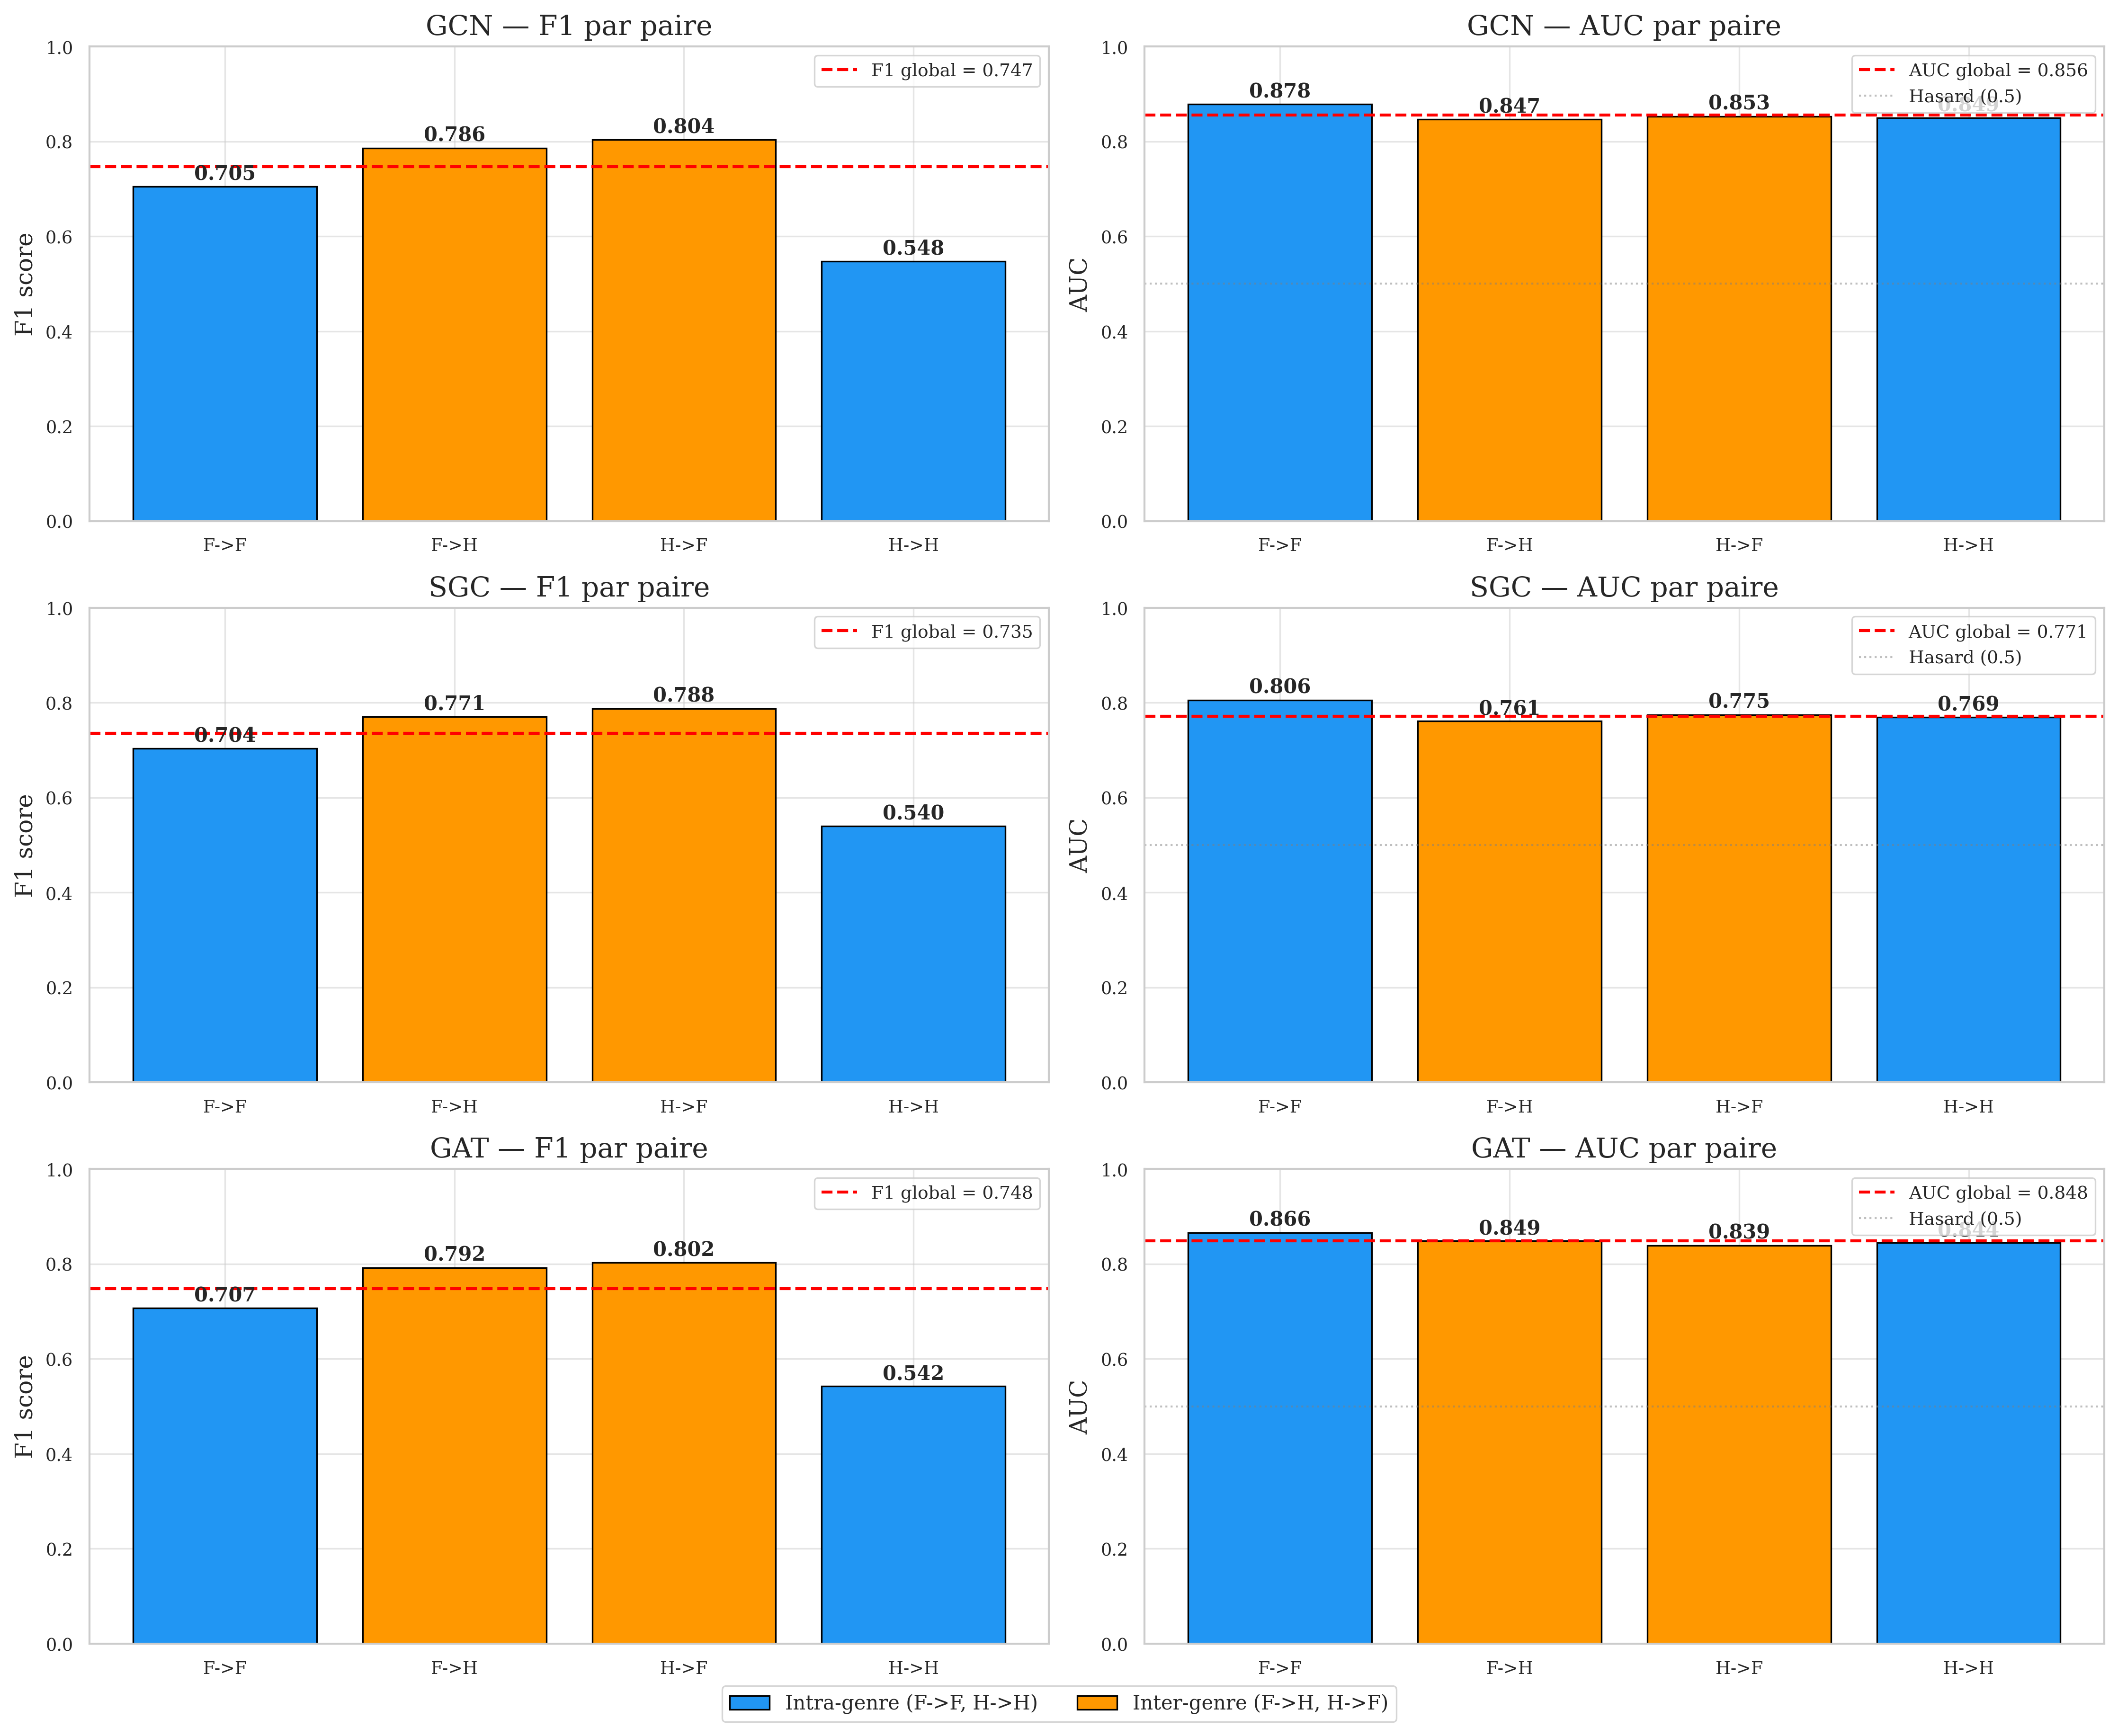

In [10]:
# Performance par type de paire (F1 et AUC)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
for i, name in enumerate(['GCN', 'SGC', 'GAT']):
    r = results[name]
    bar_per_pair(axes[i, 0], r['f']['pf1'], f'{name} — F1 par paire', 'F1 score',
                 hline=r['f1'], hline_label=f"F1 global = {r['f1']:.3f}")
    bar_per_pair(axes[i, 1], r['f']['pa'], f'{name} — AUC par paire', 'AUC',
                 hline=r['auc'], hline_label=f"AUC global = {r['auc']:.3f}",
                 extras=[(0.5, 'Hasard (0.5)', {'alpha': 0.5})])
fairness_legend(fig)
plt.tight_layout()
plt.show()

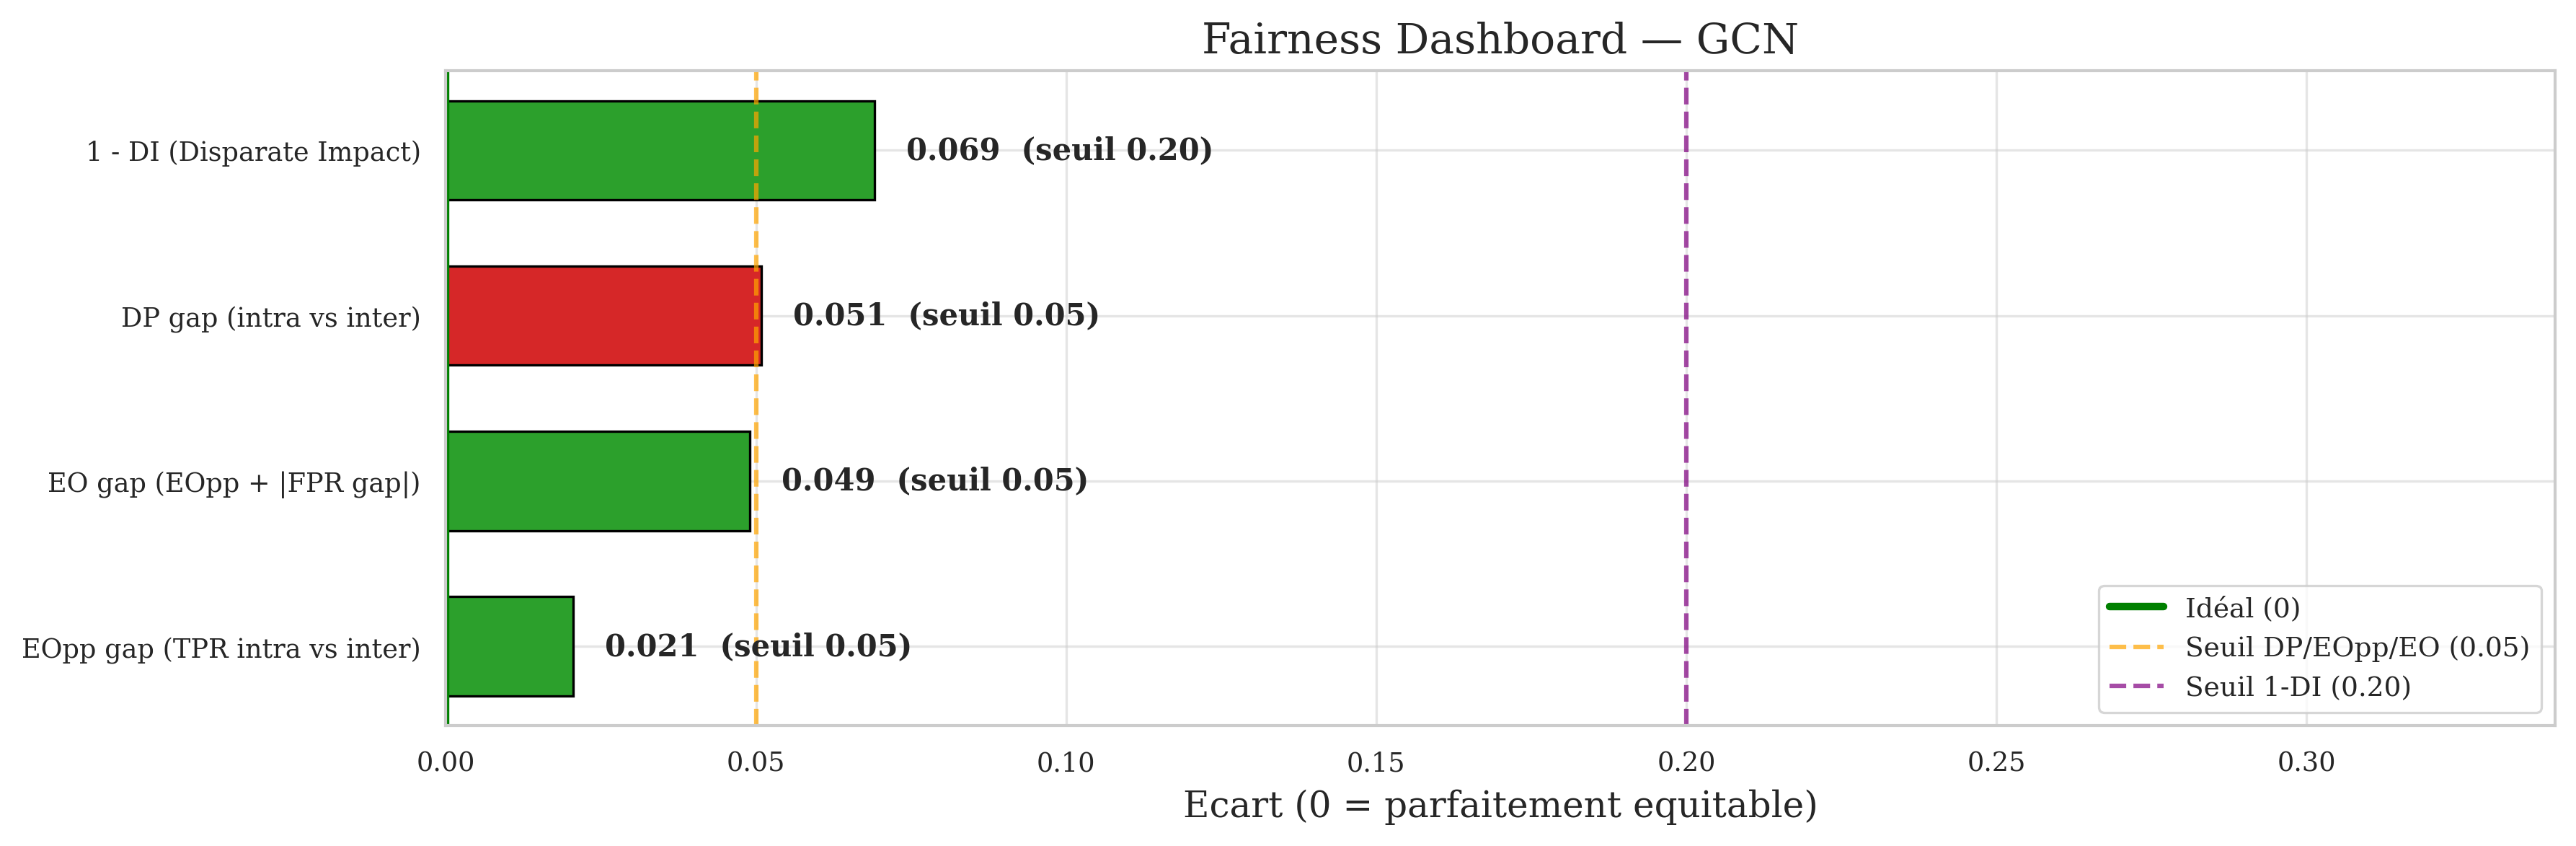

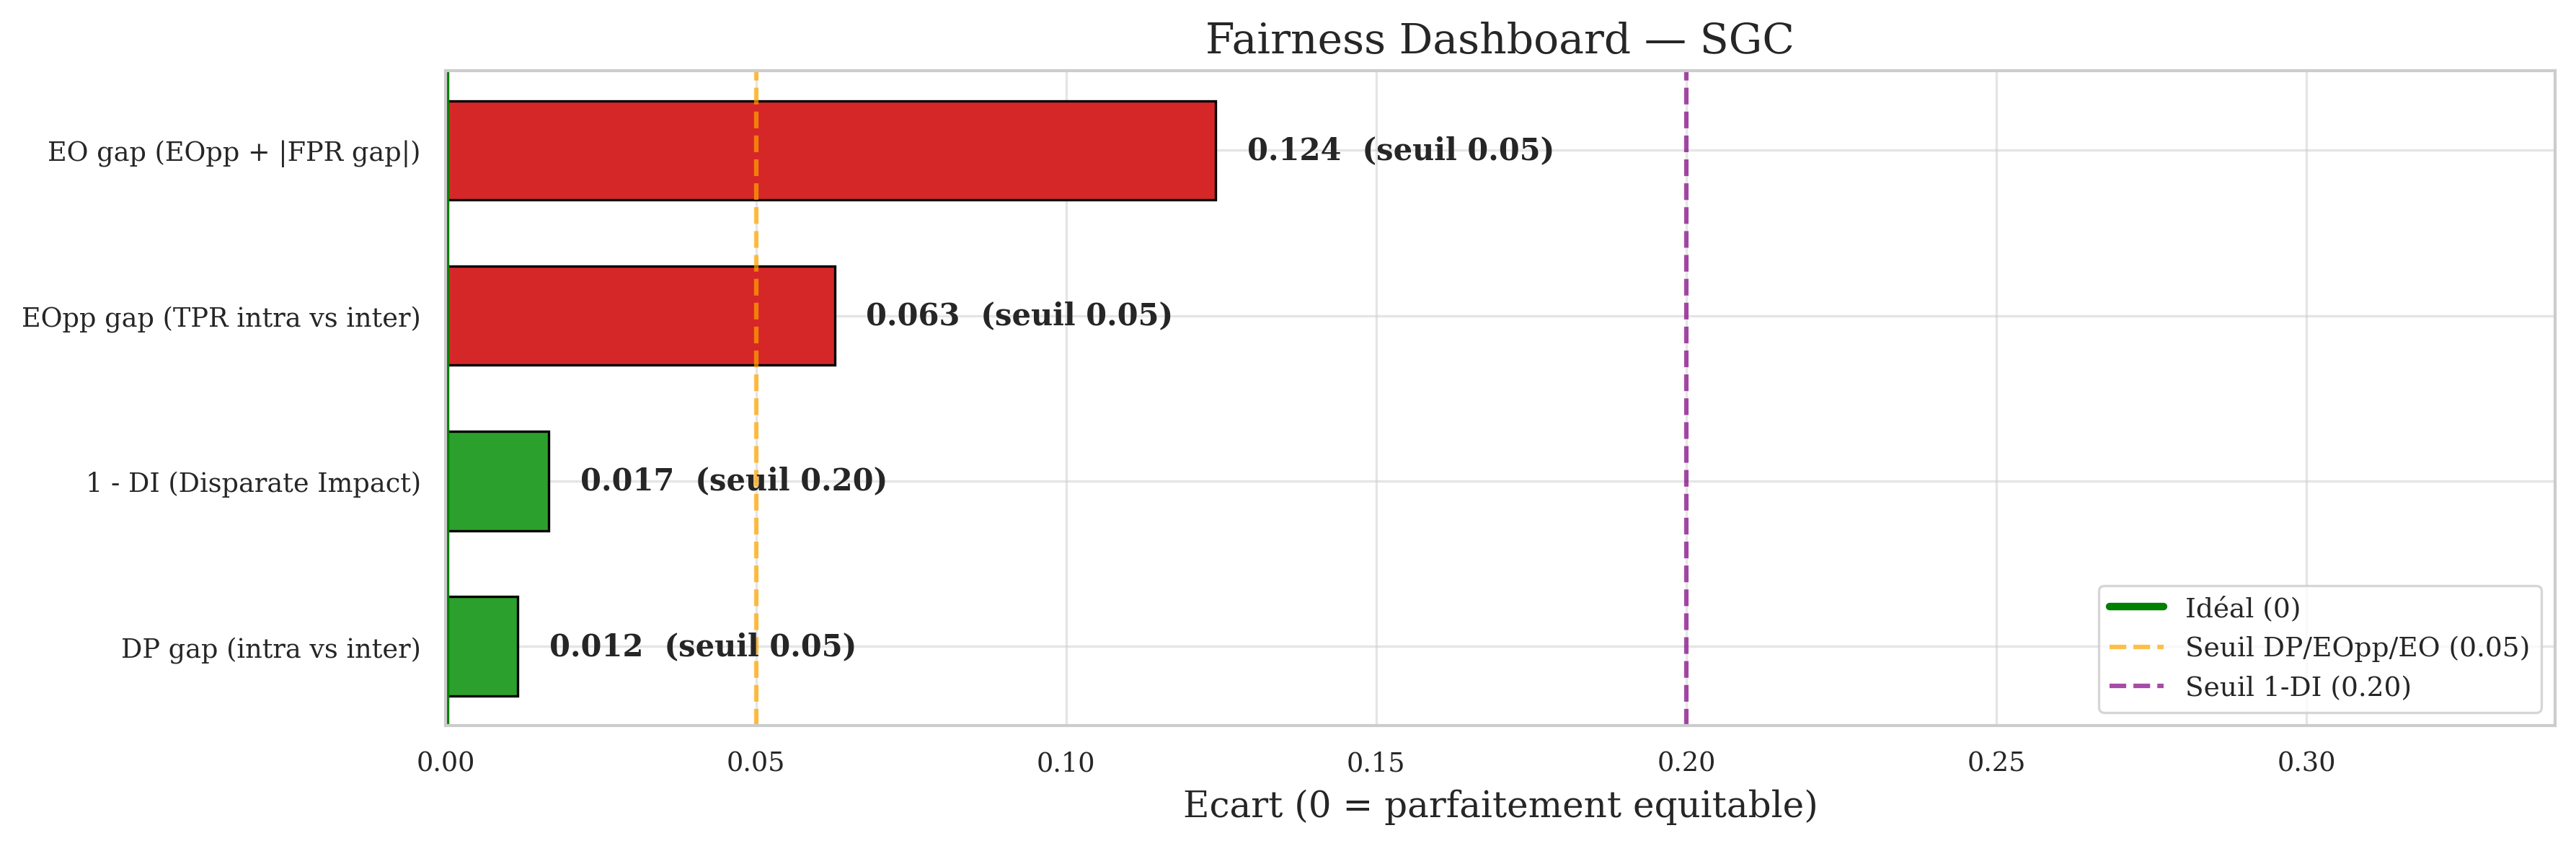

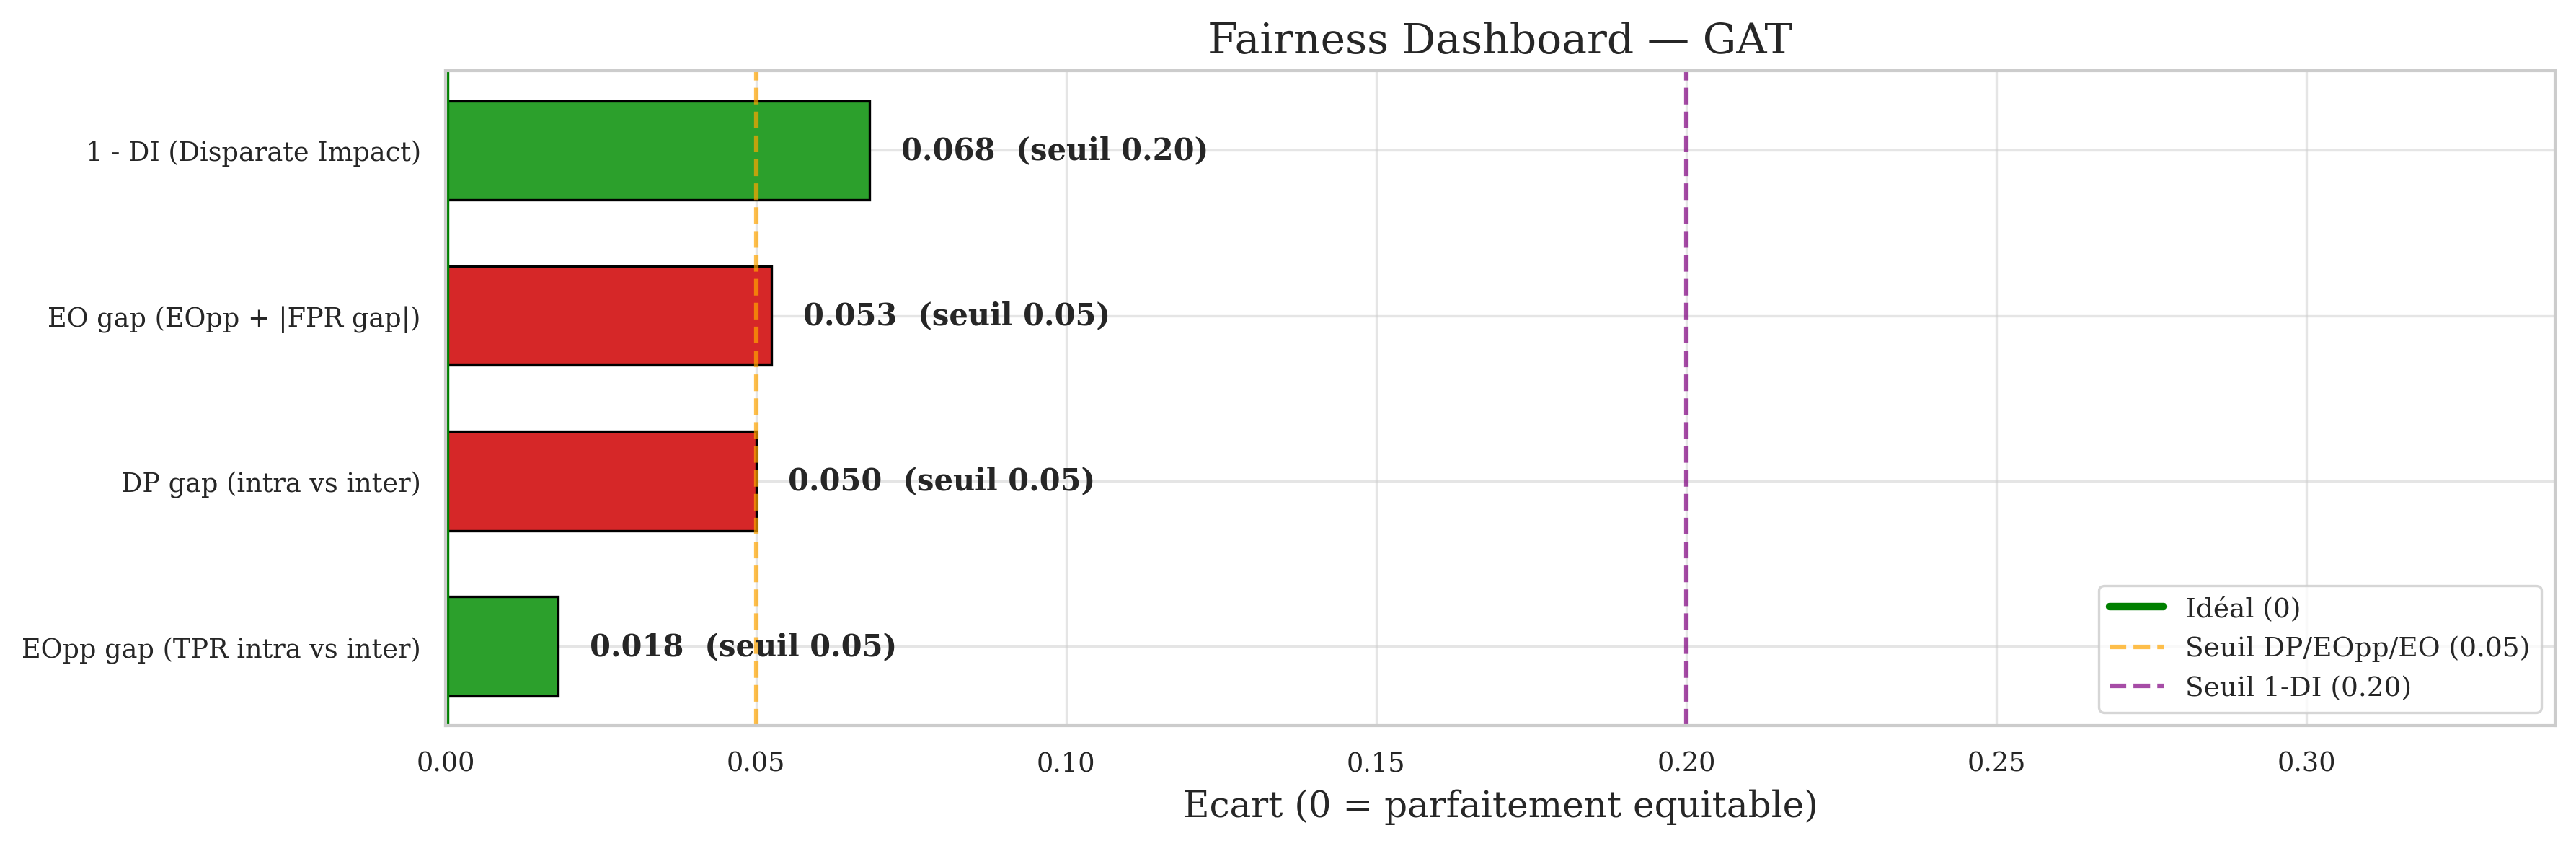

In [11]:
# Fairness dashboards
for name in ['GCN', 'SGC', 'GAT']:
    f = results[name]['f']
    metrics = [
        ('DP gap (intra vs inter)',       f['DP'],     0.05),
        ('EOpp gap (TPR intra vs inter)', f['EOpp'],   0.05),
        ('EO gap (EOpp + |FPR gap|)',     f['EO'],     0.05),
        ('1 - DI (Disparate Impact)',     1 - f['DI'], 0.20),
    ]
    barh_dashboard(metrics, title=f'Fairness Dashboard — {name}',
                   xlabel='Ecart (0 = parfaitement equitable)',
                   threshold_lines=[(0.05, 'Seuil DP/EOpp/EO (0.05)', 'orange'),
                                    (0.20, 'Seuil 1-DI (0.20)', 'purple')])
    plt.tight_layout() 
    plt.show()

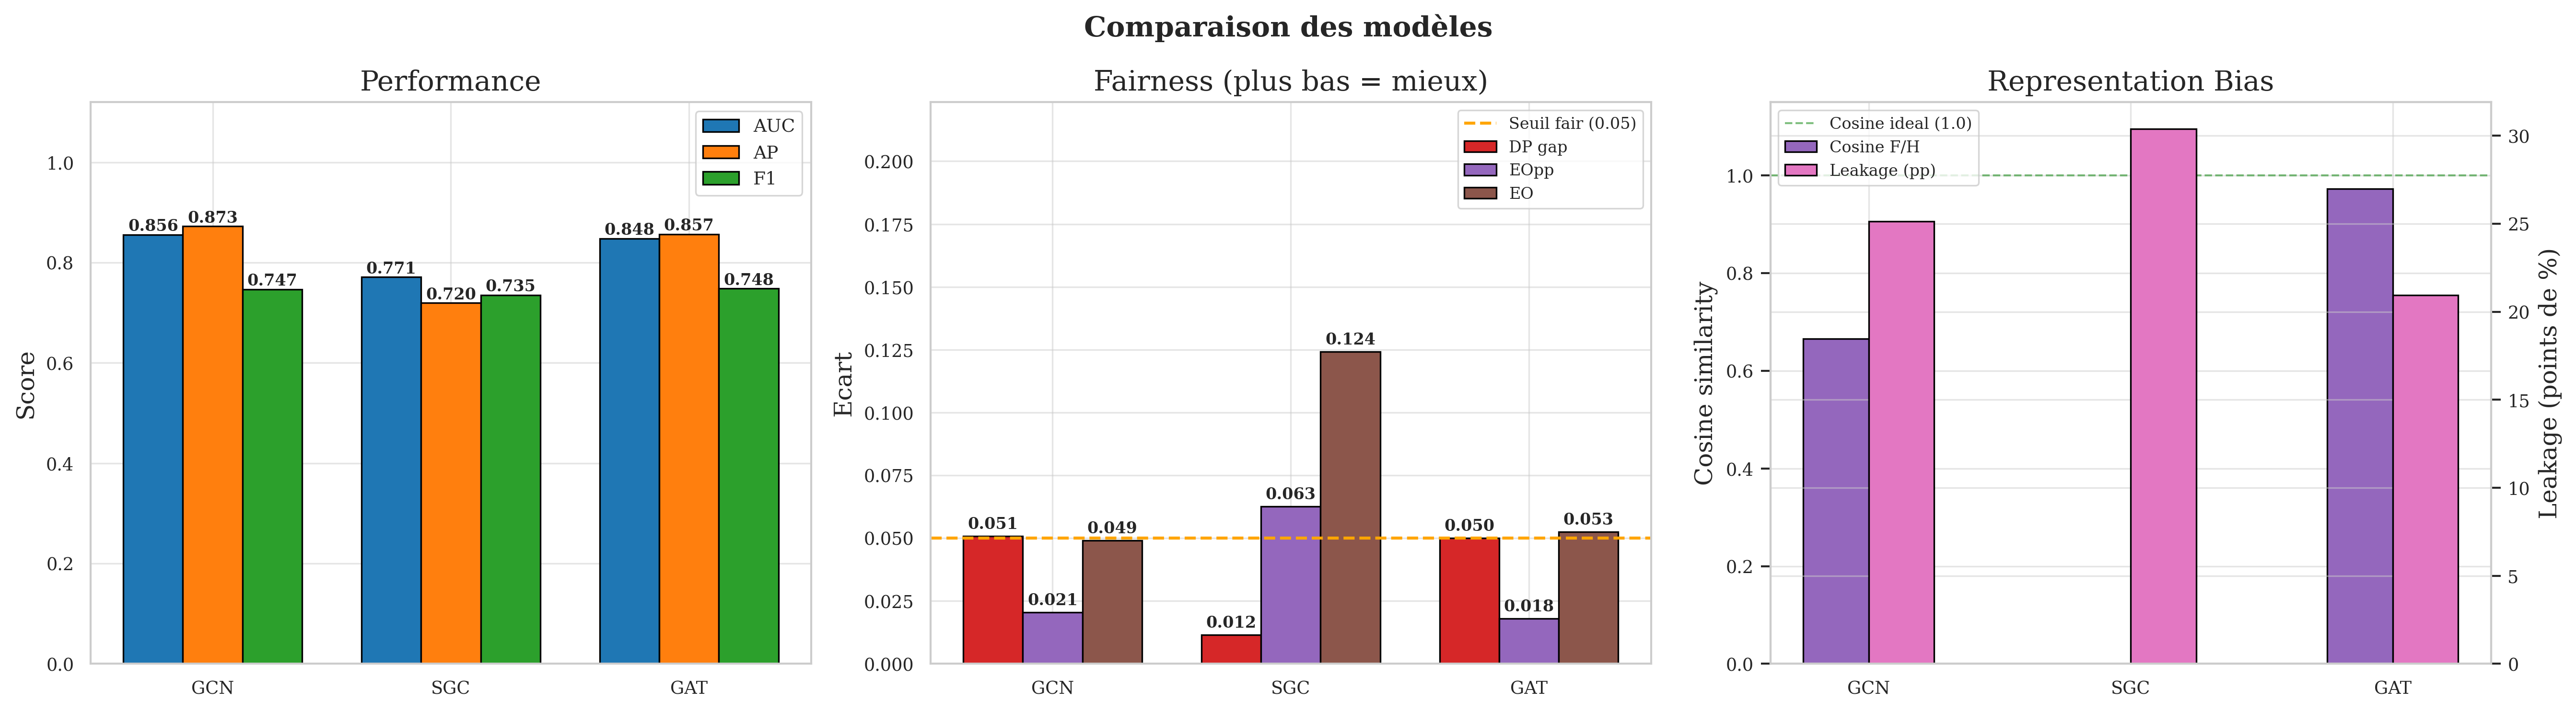

In [12]:
# Comparaison 3 panneaux : Performance / Fairness / Leakage
plot_models_comparison(results)

### Choix du modèle de référence : GCN

| Critère | GCN | SGC | GAT |
|---------|-----|-----|-----|
| AUC | **~0.856** | ~0.771 | ~0.848 |
| DP gap | 0.051 (borderline) | 0.012 | 0.051 |
| Cosine F/H | 0.667 | -0.178 | 0.972 |

**Justification** :
1. **Architecture de référence** en fairness GNN (Kipf & Welling 2017) — résultats comparables à la littérature
2. **Profil de biais idéal** : cosine = 0.667 → séparation claire des genres, suffisante pour démontrer une correction
3. **Architecture simple** → tout changement sous régularisation est attribuable au compromis perf/fairness, sans facteur confondant

Le SGC est trop faible (AUC 0.771), le GAT est déjà quasi gender-neutral (cosine 0.972).

---

## 2- Acte 2 — Diagnostic XAI : d'où vient le biais ?

Trois approches complémentaires pour localiser l'origine du biais :
1. **GNNExplainer** : quelles features expliquent les prédictions de liens ?
2. **Attention GAT** : le modèle sur-pondère-t-il les voisins du même genre ?
3. **Ablation contrefactuelle** : le biais est-il dans le feature "genre" ou dans la topologie ?

#### 2.1 GNNExplainer — Importance des features par type de paire

On explique 48 arêtes test positives (12 par type de paire) avec GNNExplainer (200 epochs, lr=0.01). Pour chaque arête, on obtient un masque d'importance sur les 64 features d'entrée.

In [13]:
# GNNExplainer : 48 arêtes test (12 par type de paire), 200 epochs
feat_imp, explain_edges, explain_pt = run_gnnexplainer(model_gcn, test_data, sens, device, n_per_type=12)

48 arêtes : F->F=12 | F->H=12 | H->F=12 | H->H=12


GNNExplainer:   0%|          | 0/48 [00:00<?, ?it/s]

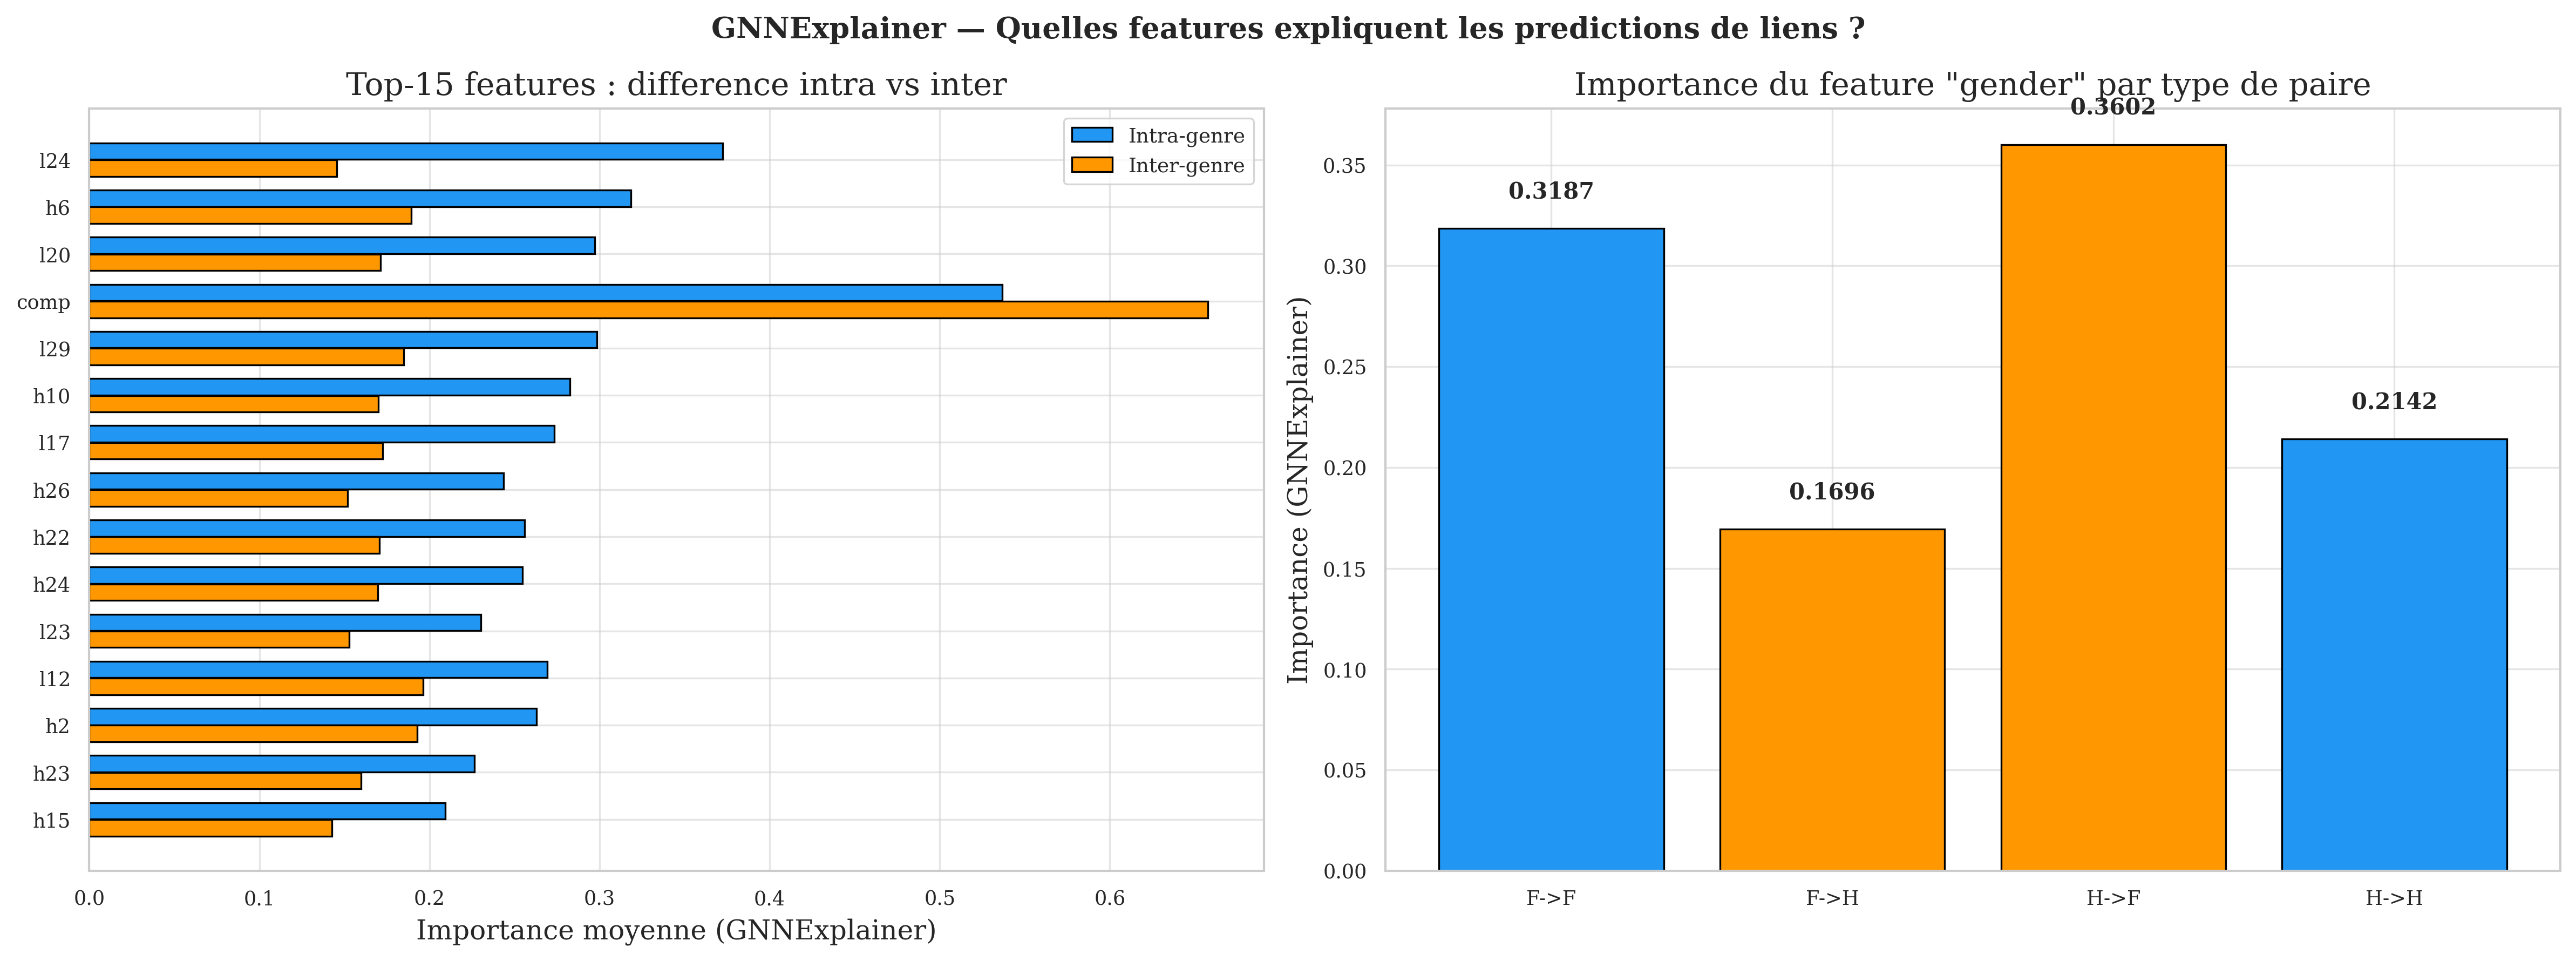

Feature 'gender' : rang 3/64 en importance globale


In [14]:
# Résultats GNNExplainer : top features + importance du genre
plot_feature_importance(feat_imp)

#### 2.2 Validation XAI — Fidelity+/-

On vérifie que les masques GNNExplainer sont fidèles au modèle :
- **Fidelity+** : masquer les K features les plus importants → la prédiction doit **chuter**
- **Fidelity-** : masquer les K features les moins importants → la prédiction doit **rester stable**

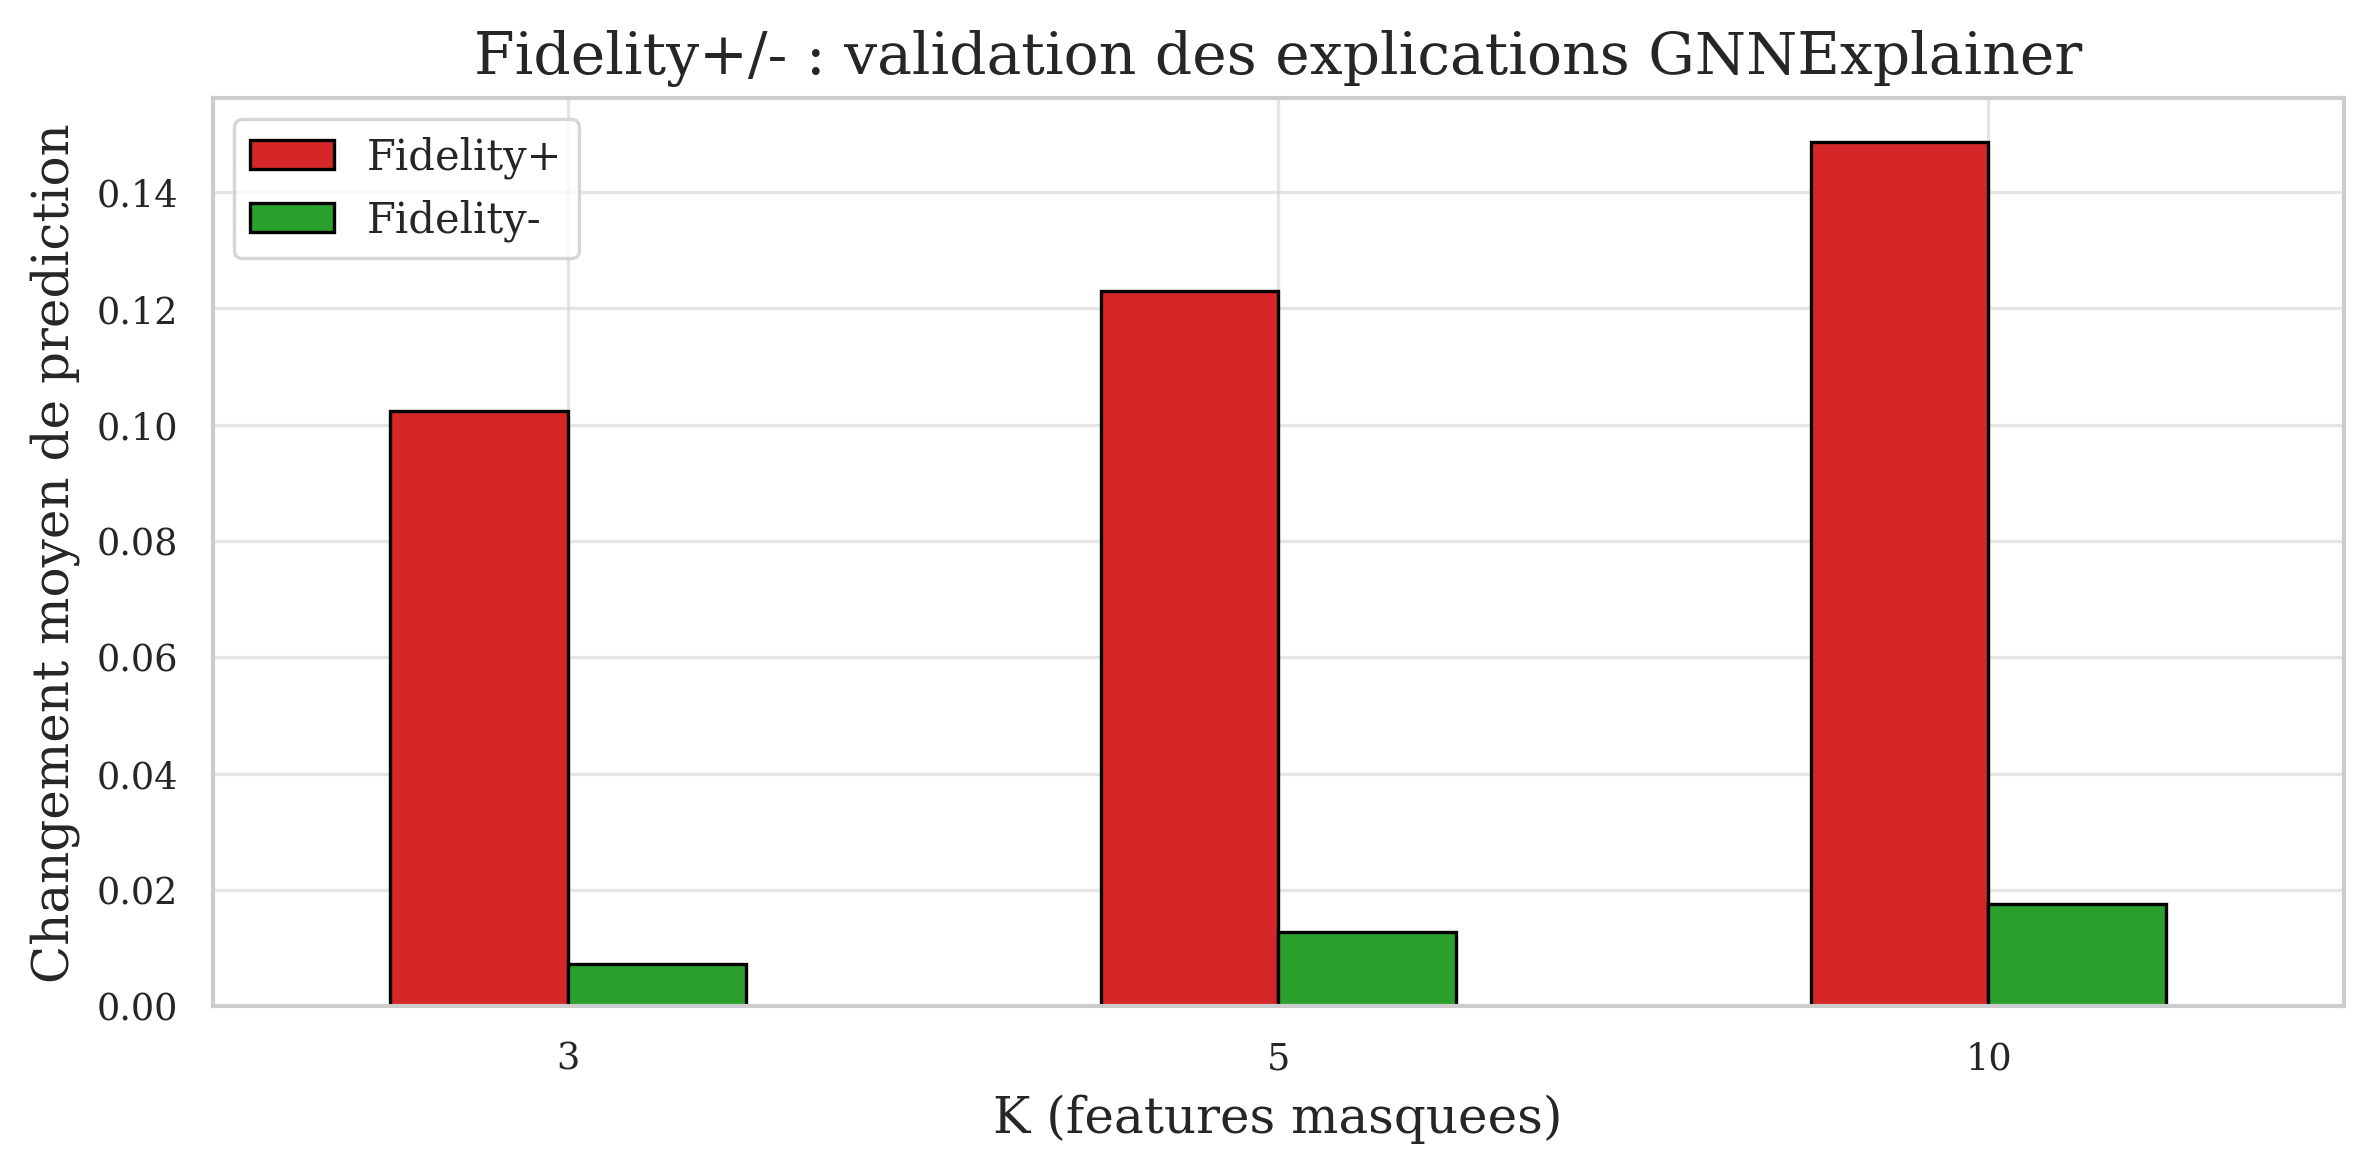

    Fidelity+  Fidelity-
K                       
3      0.1024     0.0072
5      0.1230     0.0127
10     0.1487     0.0176


In [15]:
# Fidelity+/- pour K = 3, 5, 10
df_fid = compute_fidelity(model_gcn, test_data, feat_imp, explain_edges, device, K_values=[3, 5, 10])
plot_fidelity(df_fid)

#### 2.3 Attention GAT — biais d'homophilie

Le GAT dispose d'un mécanisme d'attention natif. Question : **le modèle prête-t-il plus attention aux voisins du même genre ?**

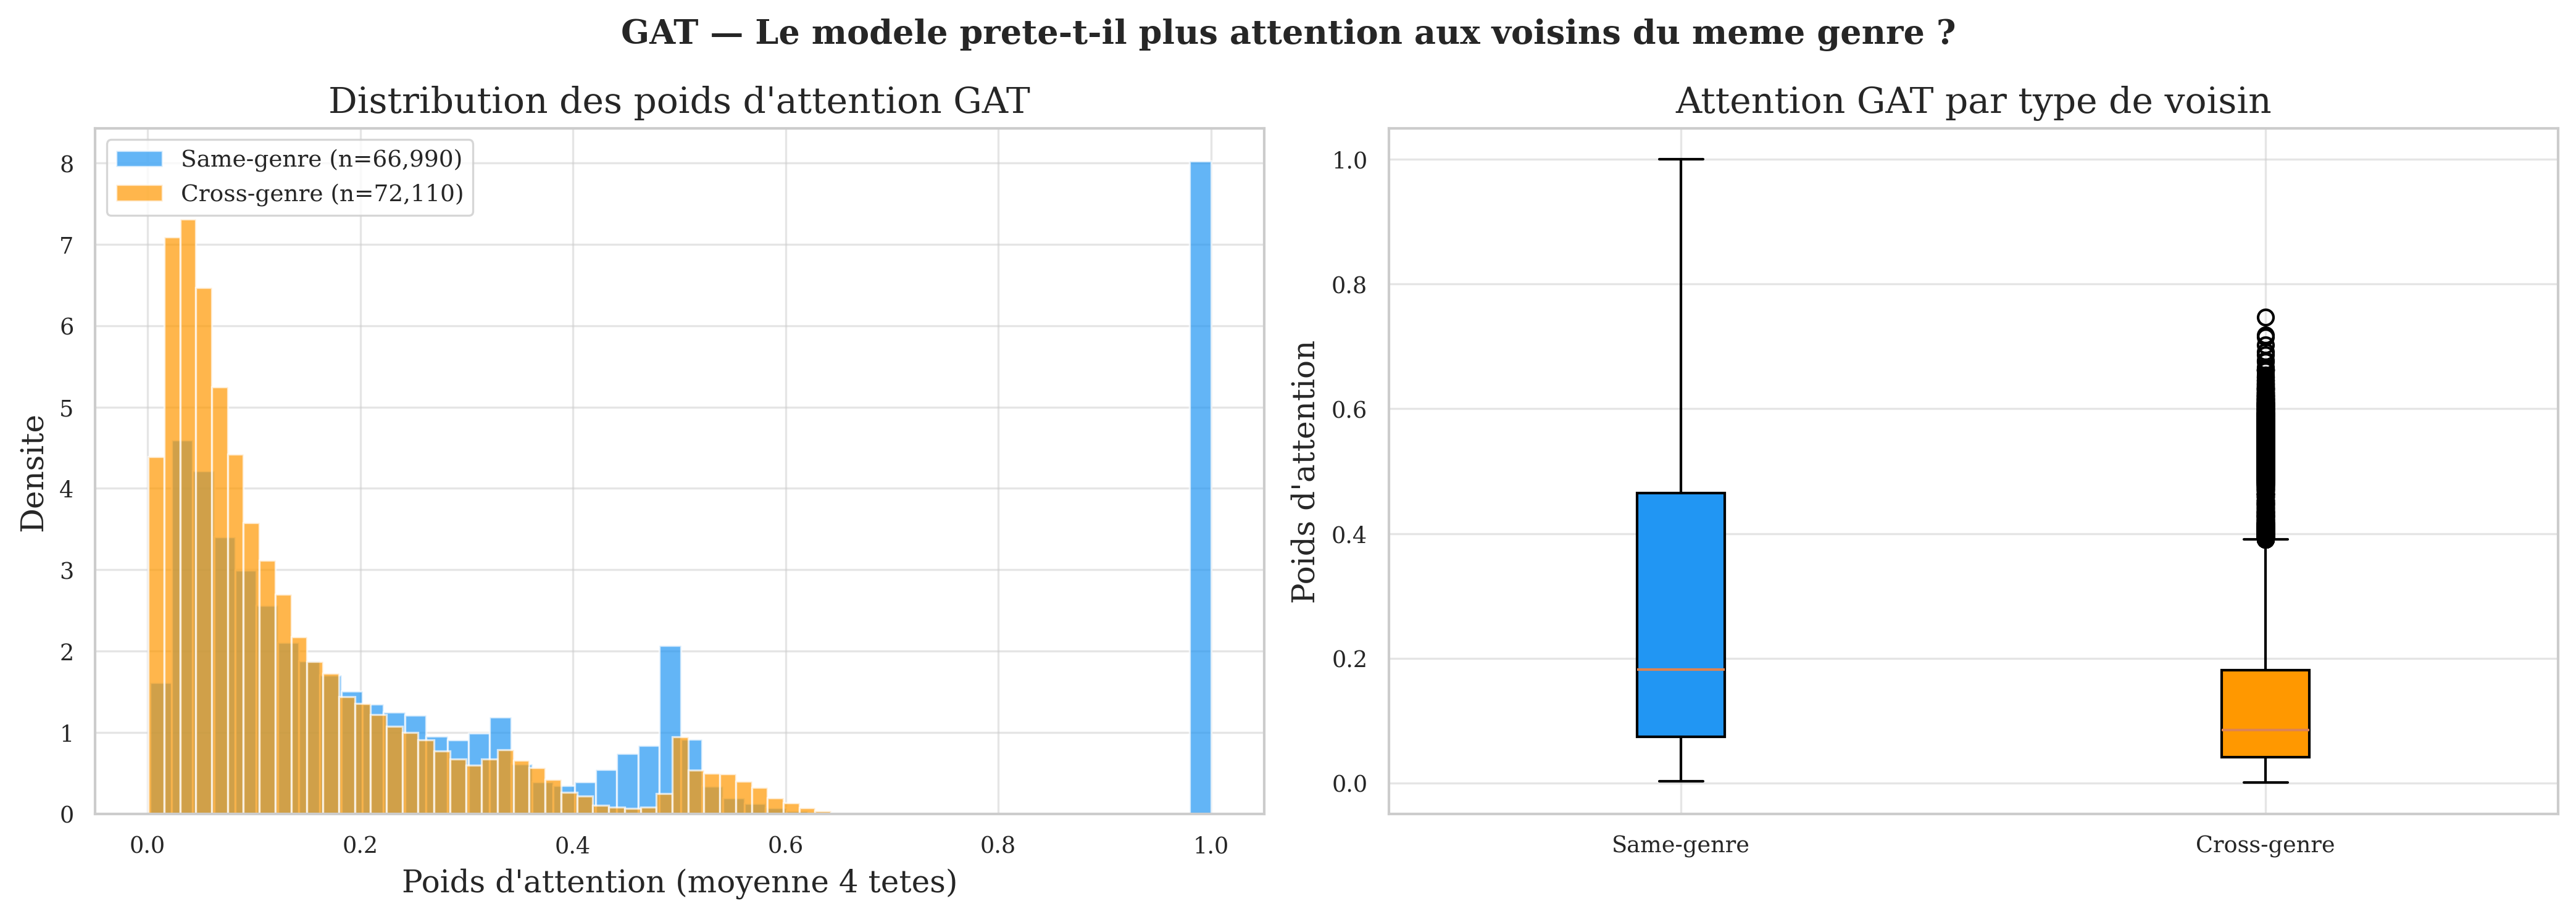

Attention same-genre  : 0.320237 | cross-genre : 0.136532 | ratio : 2.3455


In [16]:
# Extraction des poids d'attention GAT (couche 2)
model_gat.eval()
with torch.no_grad():
    _, (_, attn_layer2) = model_gat.encode(data.x.to(device), data.edge_index.to(device), return_attn=True)
    edges, alphas = attn_layer2

alphas_mean = alphas.cpu().mean(dim=1)
src_g = sens[edges.cpu()[0]]
tgt_g = sens[edges.cpu()[1]]
same_mask = (src_g == tgt_g)
att_same = alphas_mean[same_mask].numpy()
att_cross = alphas_mean[~same_mask].numpy()

plot_attention_bias(att_same, att_cross)

#### 2.4 Ablation contrefactuelle du genre

Test causal : on met à zéro le feature "gender" dans les entrées du GCN **sans réentraîner**. Si le biais persiste → il provient de la **topologie** (asymétrie structurelle du graphe), pas du feature explicite.

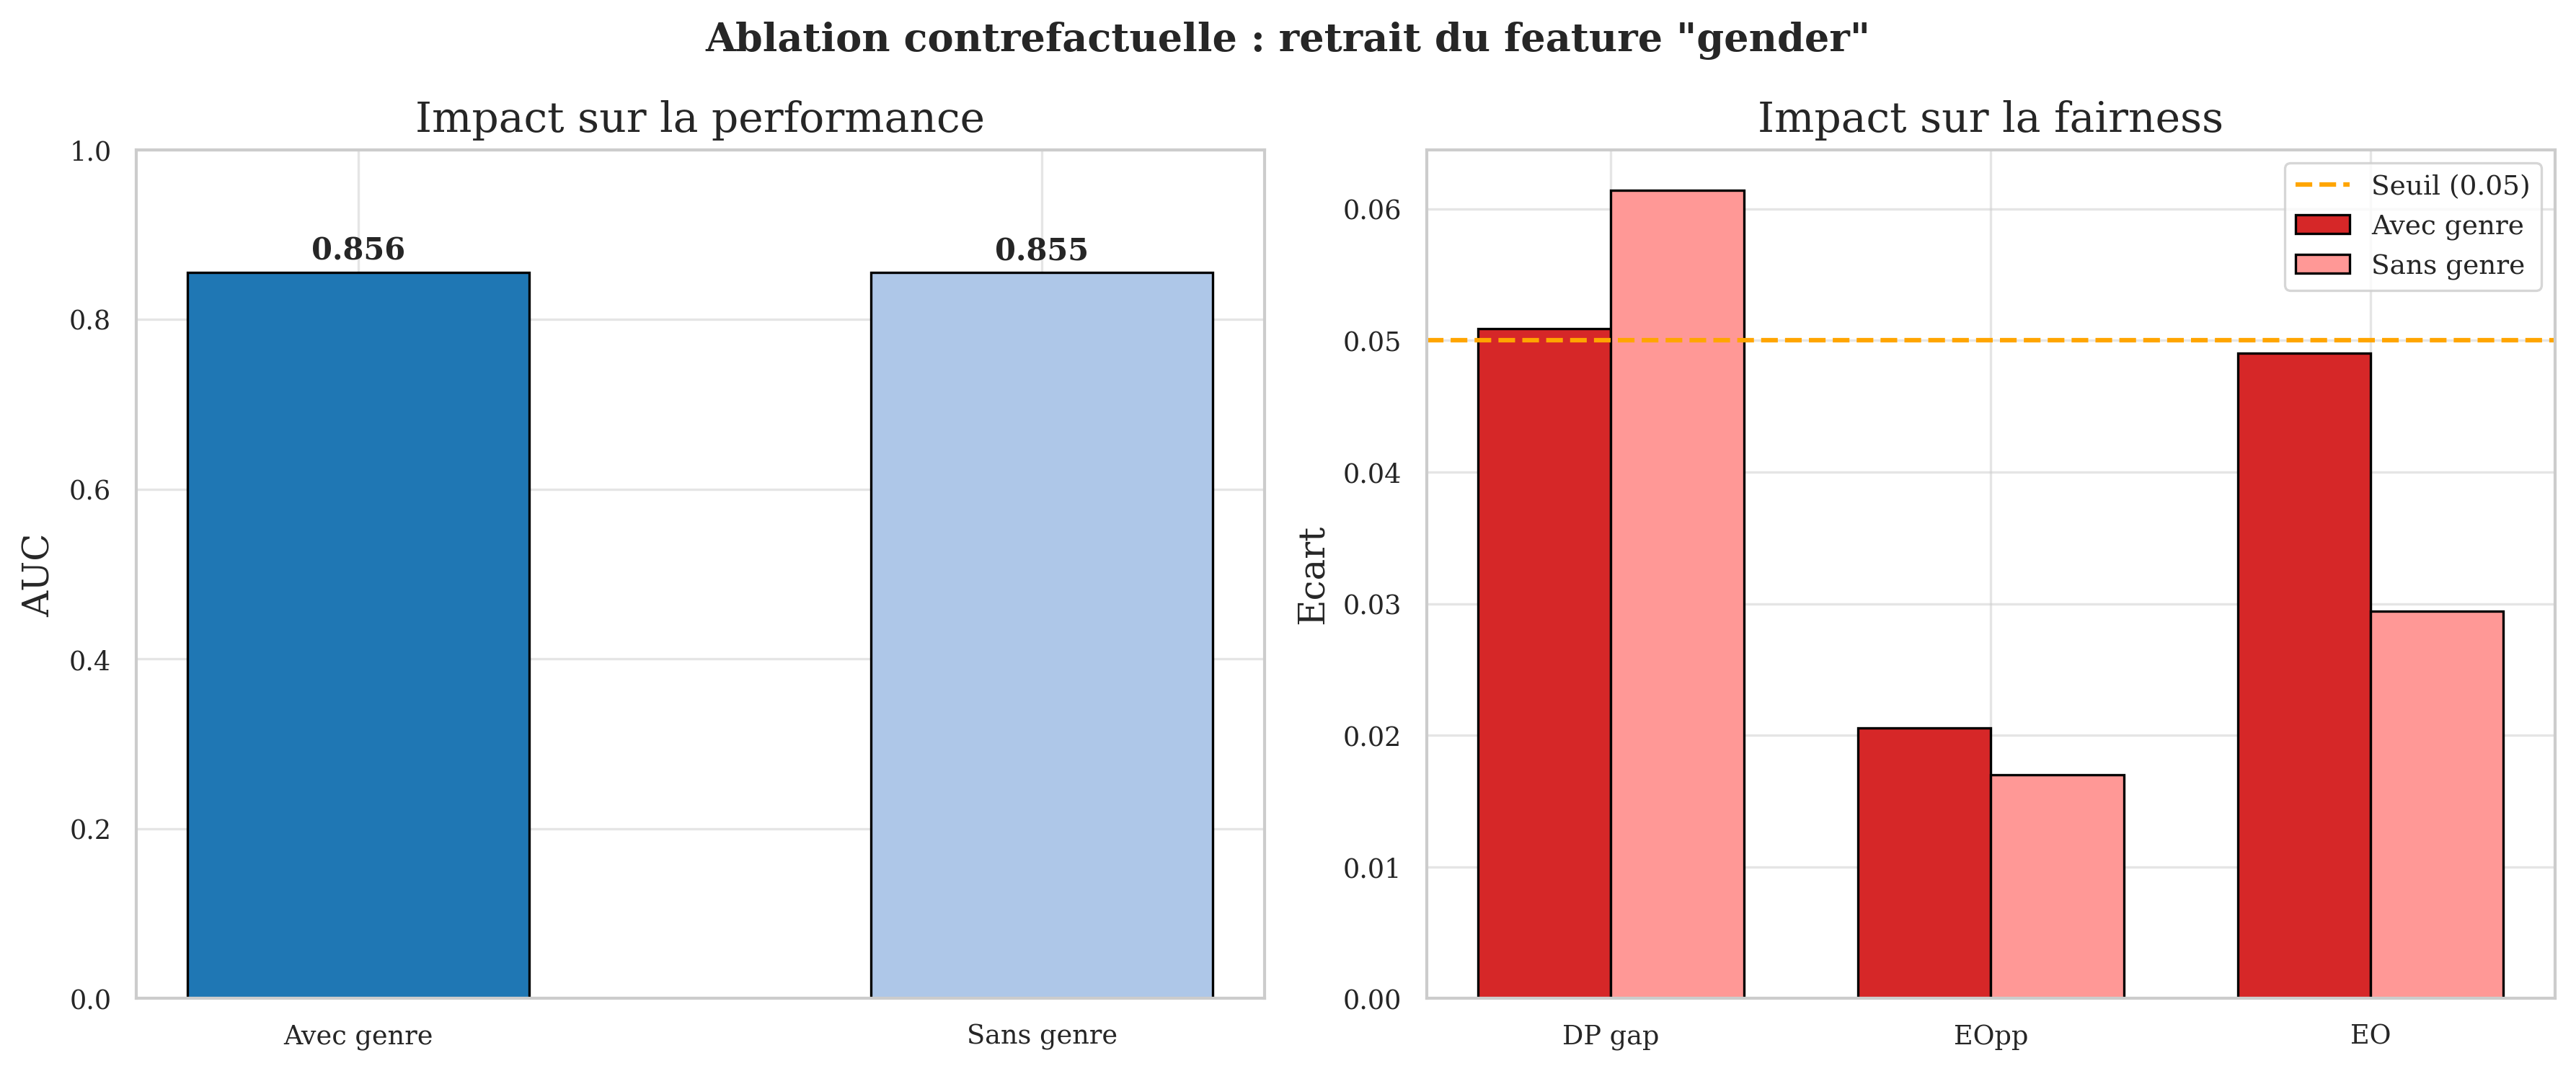

AUC : 0.8556 -> 0.8551 (delta = -0.0005)
DP  : 0.0509 -> 0.0614 (delta = +0.0105)

=> Le DP gap AUGMENTE sans le feature genre : le biais est TOPOLOGIQUE.


In [17]:
# Ablation : prédiction avec et sans le feature genre
r_abl = ablation_feature(model_gcn, test_data, sens, device)
plot_ablation(r_abl['auc_orig'], r_abl['auc_ablated'], r_abl['f_orig'], r_abl['f_ablated'])

### Bilan Acte 2

| Diagnostic | Résultat clé |
|---|---|
| GNNExplainer | `comp` et features textuels dominent ; `gender` a un rôle asymétrique par paire |
| Fidelity+/- | Explications fidèles (ratio ~10x entre top et bottom features) |
| Attention GAT | Biais d'attention clair en faveur des voisins same-genre |
| Ablation | Retirer le genre **augmente** le DP gap → biais **topologique** |

**Conclusion** : Les corrections doivent cibler la **loss et les embeddings**, pas le feature genre.

---

## 3- Acte 3 — Correction Fairness

Trois méthodes codées from scratch (pas de Fairlearn/AIF360) :

1. **Reweighting** : $w(\text{type}) = N_\text{total} / (2 \times N_\text{type})$
2. **Régularisation DP** : $\mathcal{L} = \mathcal{L}_\text{task} + \lambda \cdot |\bar{y}_\text{intra} - \bar{y}_\text{inter}|$, sweep $\lambda \in \{0.1, 0.5, 1, 5, 10\}$
3. **FairGNN adversarial** : $\mathcal{L}_\text{enc} = \mathcal{L}_\text{task} - \alpha \cdot \mathcal{L}_\text{disc}$, sweep $\alpha \in \{0.5, 1, 2, 5\}$

#### 3.1 Reweighting

In [18]:
# 3.1 Reweighting
set_seed(42)
model_rw = GCN(data.x.shape[1]).to(device)
best_auc_rw = train_fair(model_rw, train_data, val_data, sens, device,
                          epochs=100, lr=0.01, reweight=True, desc='Reweighting')
r_rw = collect_results(model_rw, test_data, sens, device)
print(f"Reweighting — AUC={r_rw['auc']:.4f} | DP={r_rw['f']['DP']:.4f} | Cos={r_rw['cos_fh']:.4f}")

  Reweighting : w_intra=1.1838, w_inter=0.8656


Reweighting:   0%|          | 0/100 [00:00<?, ?it/s]

Reweighting — AUC=0.8526 | DP=0.0562 | Cos=0.8517


#### 3.2 Régularisation DP — sweep lambda

In [19]:
# 3.2 Régularisation DP — sweep lambda
lambdas = [0.1, 0.5, 1.0, 5.0, 10.0]
act3 = {}

# Baseline
r_base = collect_results(model_gcn, test_data, sens, device)
act3['Baseline'] = r_base
act3['Reweighting'] = r_rw

for lam in lambdas:
    set_seed(42)
    mdl = GCN(data.x.shape[1]).to(device)
    train_fair(mdl, train_data, val_data, sens, device, epochs=100, lr=0.01, lam_dp=lam, desc=f'DP lam={lam}')
    r = collect_results(mdl, test_data, sens, device)
    act3[f'DP (lam={lam})'] = r
    print(f"lambda={lam:5.1f} | AUC={r['auc']:.4f} | DP={r['f']['DP']:.4f} | Cos={r['cos_fh']:.4f}")

DP lam=0.1:   0%|          | 0/100 [00:00<?, ?it/s]

lambda=  0.1 | AUC=0.8536 | DP=0.0298 | Cos=0.1900


DP lam=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

lambda=  0.5 | AUC=0.8407 | DP=0.0412 | Cos=-0.4337


DP lam=1.0:   0%|          | 0/100 [00:00<?, ?it/s]

lambda=  1.0 | AUC=0.8363 | DP=0.0252 | Cos=-0.4698


DP lam=5.0:   0%|          | 0/100 [00:00<?, ?it/s]

lambda=  5.0 | AUC=0.8189 | DP=0.0109 | Cos=-0.3945


DP lam=10.0:   0%|          | 0/100 [00:00<?, ?it/s]

lambda= 10.0 | AUC=0.7951 | DP=0.0166 | Cos=0.5367


#### 3.3 FairGNN — sweep alpha

In [20]:
# 3.3 FairGNN — sweep alpha
alphas_fgnn = [0.5, 1.0, 2.0, 5.0]
for alpha in alphas_fgnn:
    set_seed(42)
    mdl = GCN(data.x.shape[1]).to(device)
    train_fairgnn(mdl, train_data, val_data, sens, device, alpha=alpha, epochs=100, desc=f'FairGNN a={alpha}')
    r = collect_results(mdl, test_data, sens, device)
    act3[f'FairGNN (a={alpha})'] = r
    print(f"alpha={alpha:4.1f} | AUC={r['auc']:.4f} | DP={r['f']['DP']:.4f} | Cos={r['cos_fh']:.4f}")

print(f"\nTotal : {len(act3)} configurations évaluées.")

FairGNN a=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

alpha= 0.5 | AUC=0.8490 | DP=0.0048 | Cos=-0.1592


FairGNN a=1.0:   0%|          | 0/100 [00:00<?, ?it/s]

alpha= 1.0 | AUC=0.8441 | DP=0.0286 | Cos=-0.3946


FairGNN a=2.0:   0%|          | 0/100 [00:00<?, ?it/s]

alpha= 2.0 | AUC=0.8382 | DP=0.0704 | Cos=-0.5944


FairGNN a=5.0:   0%|          | 0/100 [00:00<?, ?it/s]

alpha= 5.0 | AUC=0.8222 | DP=0.0934 | Cos=-0.7156

Total : 11 configurations évaluées.


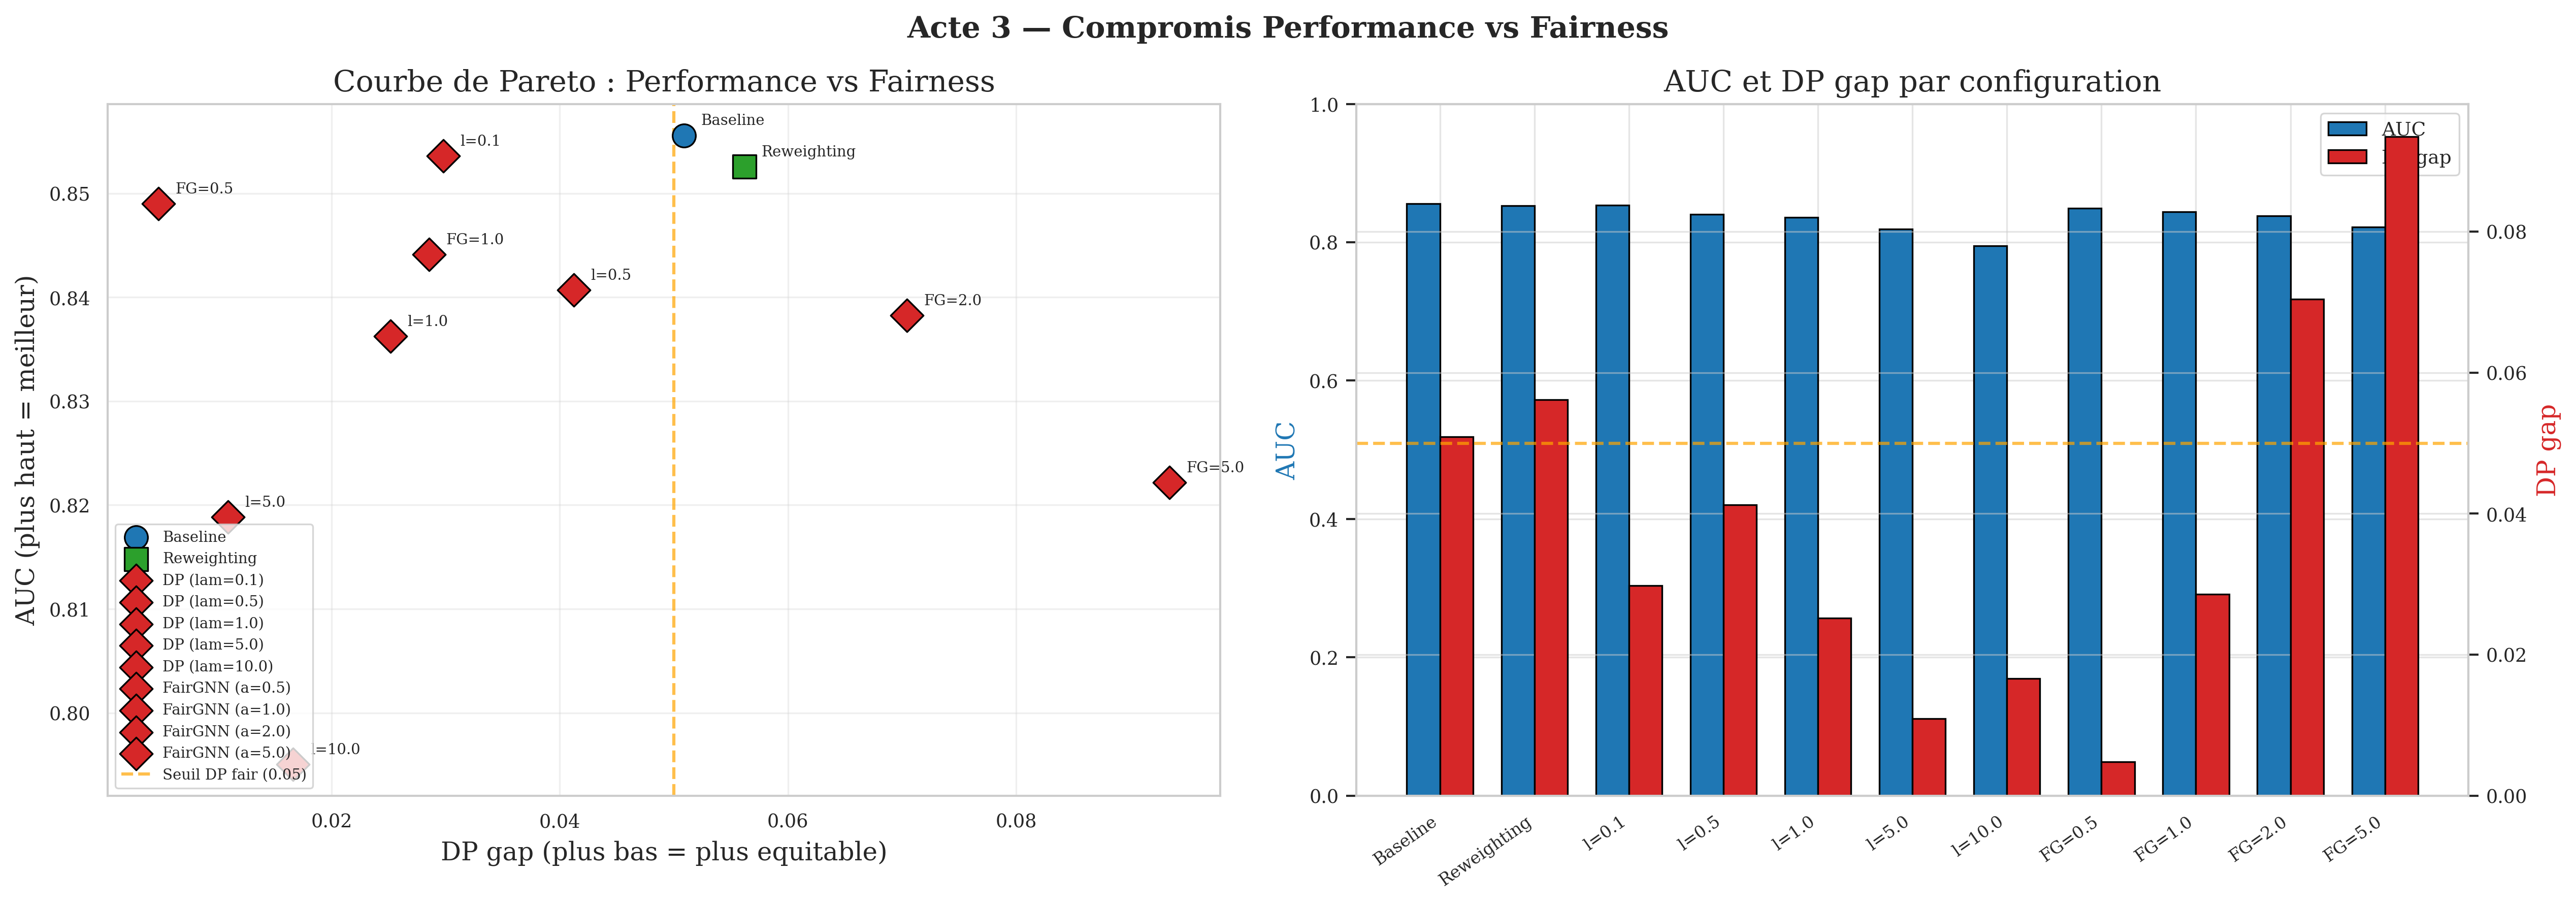

In [21]:
# 3.4 Courbe de Pareto + visualisation
plot_pareto(act3)

#### 3.4 - Récapitulatif des résultats

In [22]:
# Tableau récapitulatif complet
df_act3 = pd.DataFrame({
    name: {
        'AUC': f"{r['auc']:.4f}", 'AP': f"{r['ap']:.4f}", 'F1': f"{r['f1']:.4f}",
        'DP gap': f"{r['f']['DP']:.4f}", 'EOpp': f"{r['f']['EOpp']:.4f}",
        'DI': f"{r['f']['DI']:.4f}", 'Cosine F/H': f"{r['cos_fh']:.4f}",
        'Leakage': f"{100*r['leakage']:+.1f} pp",
    } for name, r in act3.items()
}).T
df_act3

,AUC,AP,F1,DP gap,EOpp,DI,Cosine F/H,Leakage
Baseline,0.8556,0.8725,0.7468,0.0509,0.0205,0.9309,0.6652,+25.1 pp
Reweighting,0.8526,0.8693,0.7466,0.0562,0.0199,0.9236,0.8517,+17.4 pp
DP (lam=0.1),0.8536,0.8704,0.7467,0.0298,0.0286,0.9591,0.1900,+30.3 pp
DP (lam=0.5),0.8407,0.8568,0.7486,0.0412,0.0520,0.9440,-0.4337,+34.1 pp
DP (lam=1.0),0.8363,0.8509,0.7470,0.0252,0.0493,0.9653,-0.4698,+33.9 pp
DP (lam=5.0),0.8189,0.8292,0.7454,0.0109,0.0497,0.9849,-0.3945,+31.3 pp
DP (lam=10.0),0.7951,0.7709,0.7382,0.0166,0.0409,0.9780,0.5367,+29.9 pp
FairGNN (a=0.5),0.8490,0.8647,0.7476,0.0048,0.0367,0.9932,-0.1592,+34.8 pp
FairGNN (a=1.0),0.8441,0.8594,0.7476,0.0286,0.0429,0.9606,-0.3946,+35.3 pp
FairGNN (a=2.0),0.8382,0.8458,0.7484,0.0704,0.0529,0.9064,-0.5944,+35.5 pp


### Bilan Acte 3

Le front de Pareto révèle un **coude net** autour de $\lambda = 0.1$ :
- En dessous, la correction est quasi-gratuite (DP < 0.05, AUC préservée)
- Au-dessus, chaque gain de fairness coûte de plus en plus de performance

**Meilleur compromis** : DP ($\lambda$=0.1) ou FairGNN ($\alpha$=0.5) selon la priorité.

---

## 4- Acte 4 — Validation & Incertitude

On vérifie que les corrections sont **robustes** et **bien calibrées** :
1. MC Dropout (T=30) — incertitude par type de paire
2. ECE + Reliability diagram — calibration
3. Perturbation de features — robustesse au bruit
4. Suppression d'arêtes (10%) — robustesse structurelle
5. Synthèse 3D — radar Performance / Fairness / Robustesse

In [23]:
# Ré-entraînement des 2 modèles corrigés pour l'Acte 4
set_seed(42)
model_dp01 = GCN(data.x.shape[1]).to(device)
train_fair(model_dp01, train_data, val_data, sens, device, epochs=100, lam_dp=0.1, desc='DP lam=0.1')

set_seed(42)
model_fgnn05 = GCN(data.x.shape[1]).to(device)
train_fairgnn(model_fgnn05, train_data, val_data, sens, device, alpha=0.5, epochs=100, desc='FairGNN a=0.5')

models_act4 = {'Baseline': model_gcn, 'DP (lam=0.1)': model_dp01, 'FairGNN (a=0.5)': model_fgnn05}
for name, mdl in models_act4.items():
    r = collect_results(mdl, test_data, sens, device)
    print(f"  {name:18s} | AUC={r['auc']:.4f} | DP={r['f']['DP']:.4f}")

DP lam=0.1:   0%|          | 0/100 [00:00<?, ?it/s]

FairGNN a=0.5:   0%|          | 0/100 [00:00<?, ?it/s]

  Baseline           | AUC=0.8556 | DP=0.0509
  DP (lam=0.1)       | AUC=0.8536 | DP=0.0294
  FairGNN (a=0.5)    | AUC=0.8489 | DP=0.0041


#### 4.1 MC Dropout (T=30) — Incertitude par type de paire

Baseline           | H moy=0.5486 | Var moy=0.010507 | MI moy=0.025738
DP (lam=0.1)       | H moy=0.5523 | Var moy=0.010301 | MI moy=0.025149
FairGNN (a=0.5)    | H moy=0.5553 | Var moy=0.010834 | MI moy=0.026422


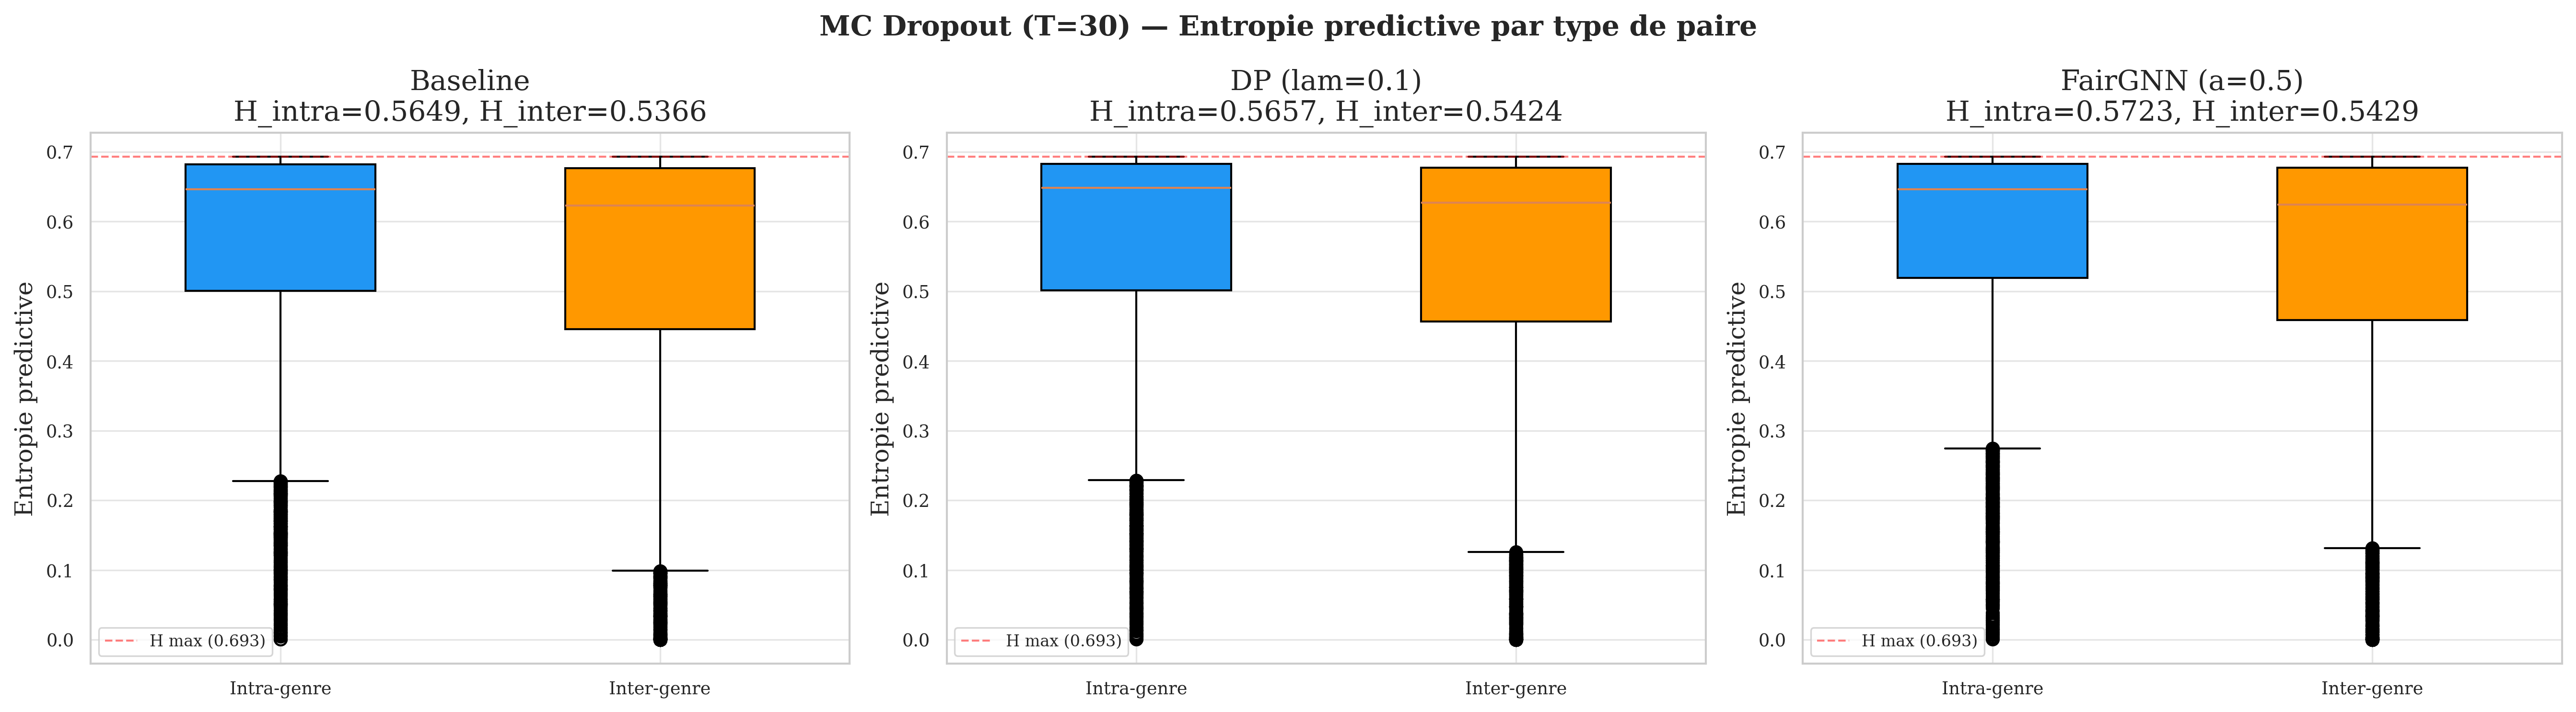

In [24]:
# 4.1 MC Dropout (T=30) — Incertitude par type de paire
T = 30
mc_results = {}
for name, mdl in models_act4.items():
    p_bar, entropy, variance, mi, all_probs = mc_dropout_predict(mdl, test_data, device, T=T)
    mc_results[name] = {'p_bar': p_bar, 'entropy': entropy, 'variance': variance, 'mi': mi}
    print(f"{name:18s} | H moy={entropy.mean():.4f} | Var moy={variance.mean():.6f} | MI moy={mi.mean():.6f}")

# Visualisation : boxplots entropie par type de paire
tpt_test = classify_pairs(test_data.edge_label_index, sens).numpy()
plot_mc_entropy(mc_results, tpt_test, T=T)

#### 4.2 ECE + Reliability Diagrams

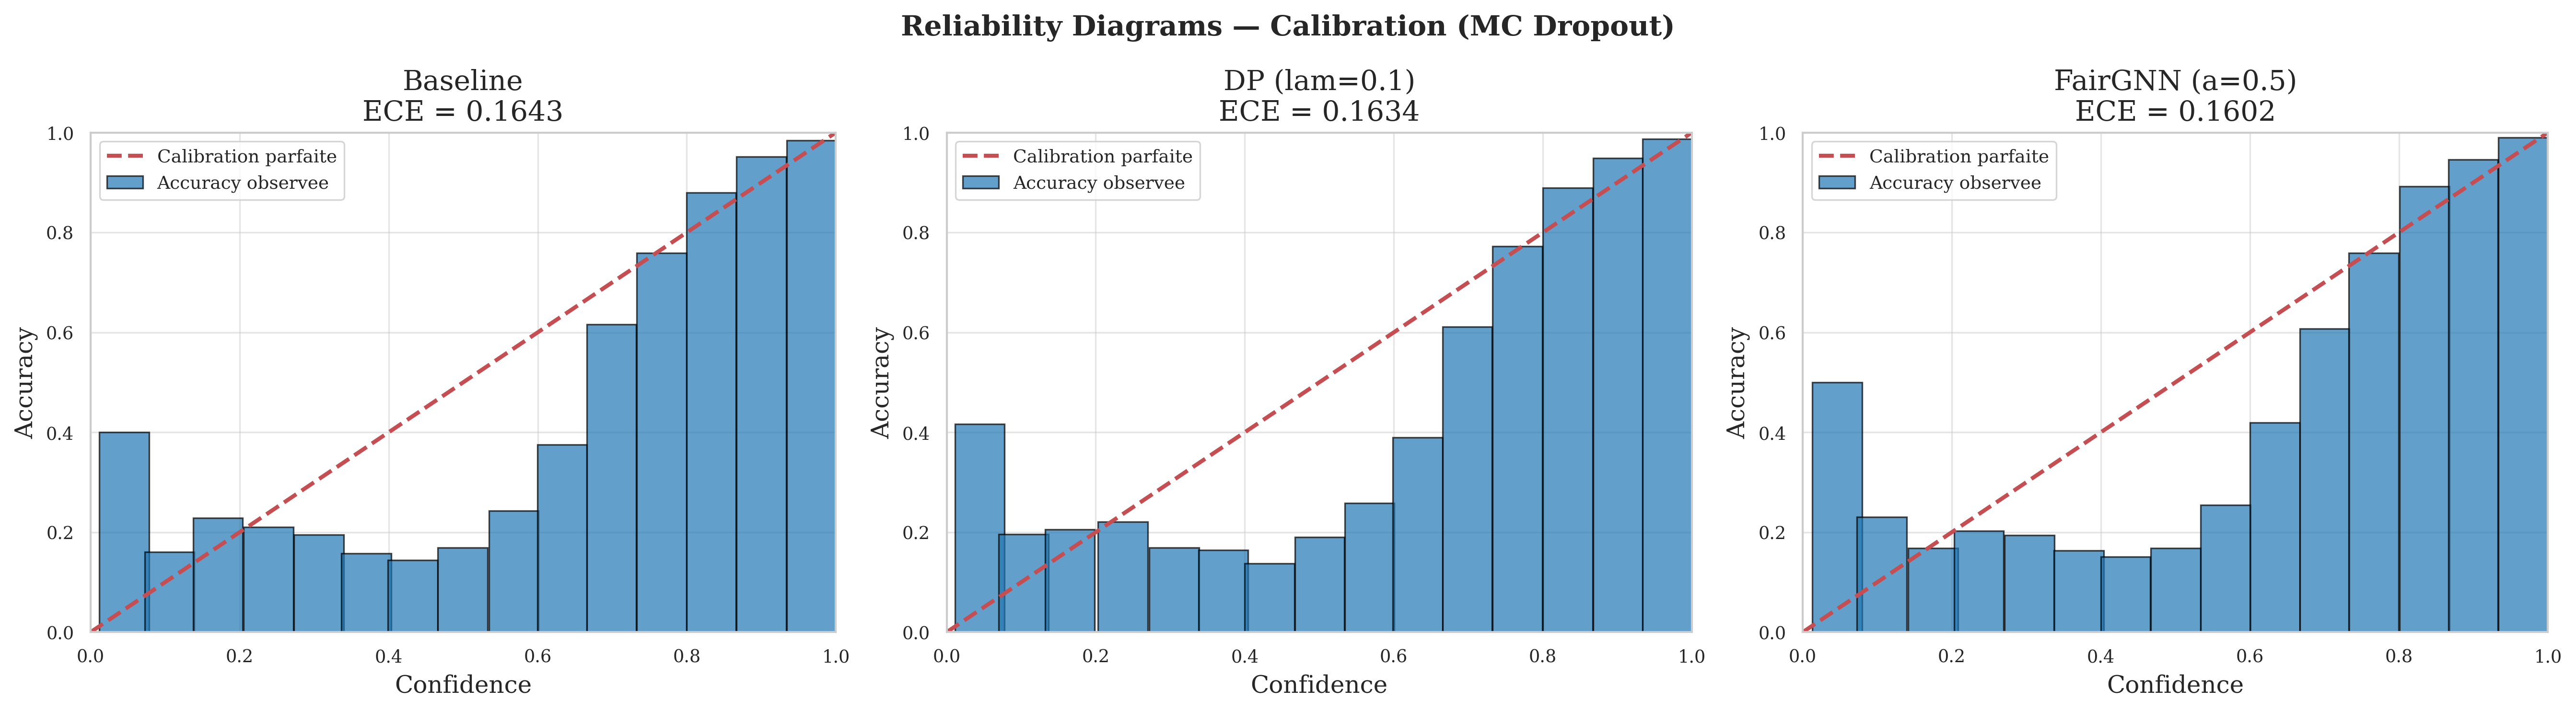

  Baseline           | ECE = 0.1643 (mal calibre)
  DP (lam=0.1)       | ECE = 0.1634 (mal calibre)
  FairGNN (a=0.5)    | ECE = 0.1602 (mal calibre)


In [25]:
# 4.2 ECE + Reliability Diagrams
labels_test = test_data.edge_label.numpy()
ece_values = plot_reliability_diagrams(mc_results, labels_test, n_bins=15)

#### 4.3 Perturbation de features — robustesse au bruit gaussien

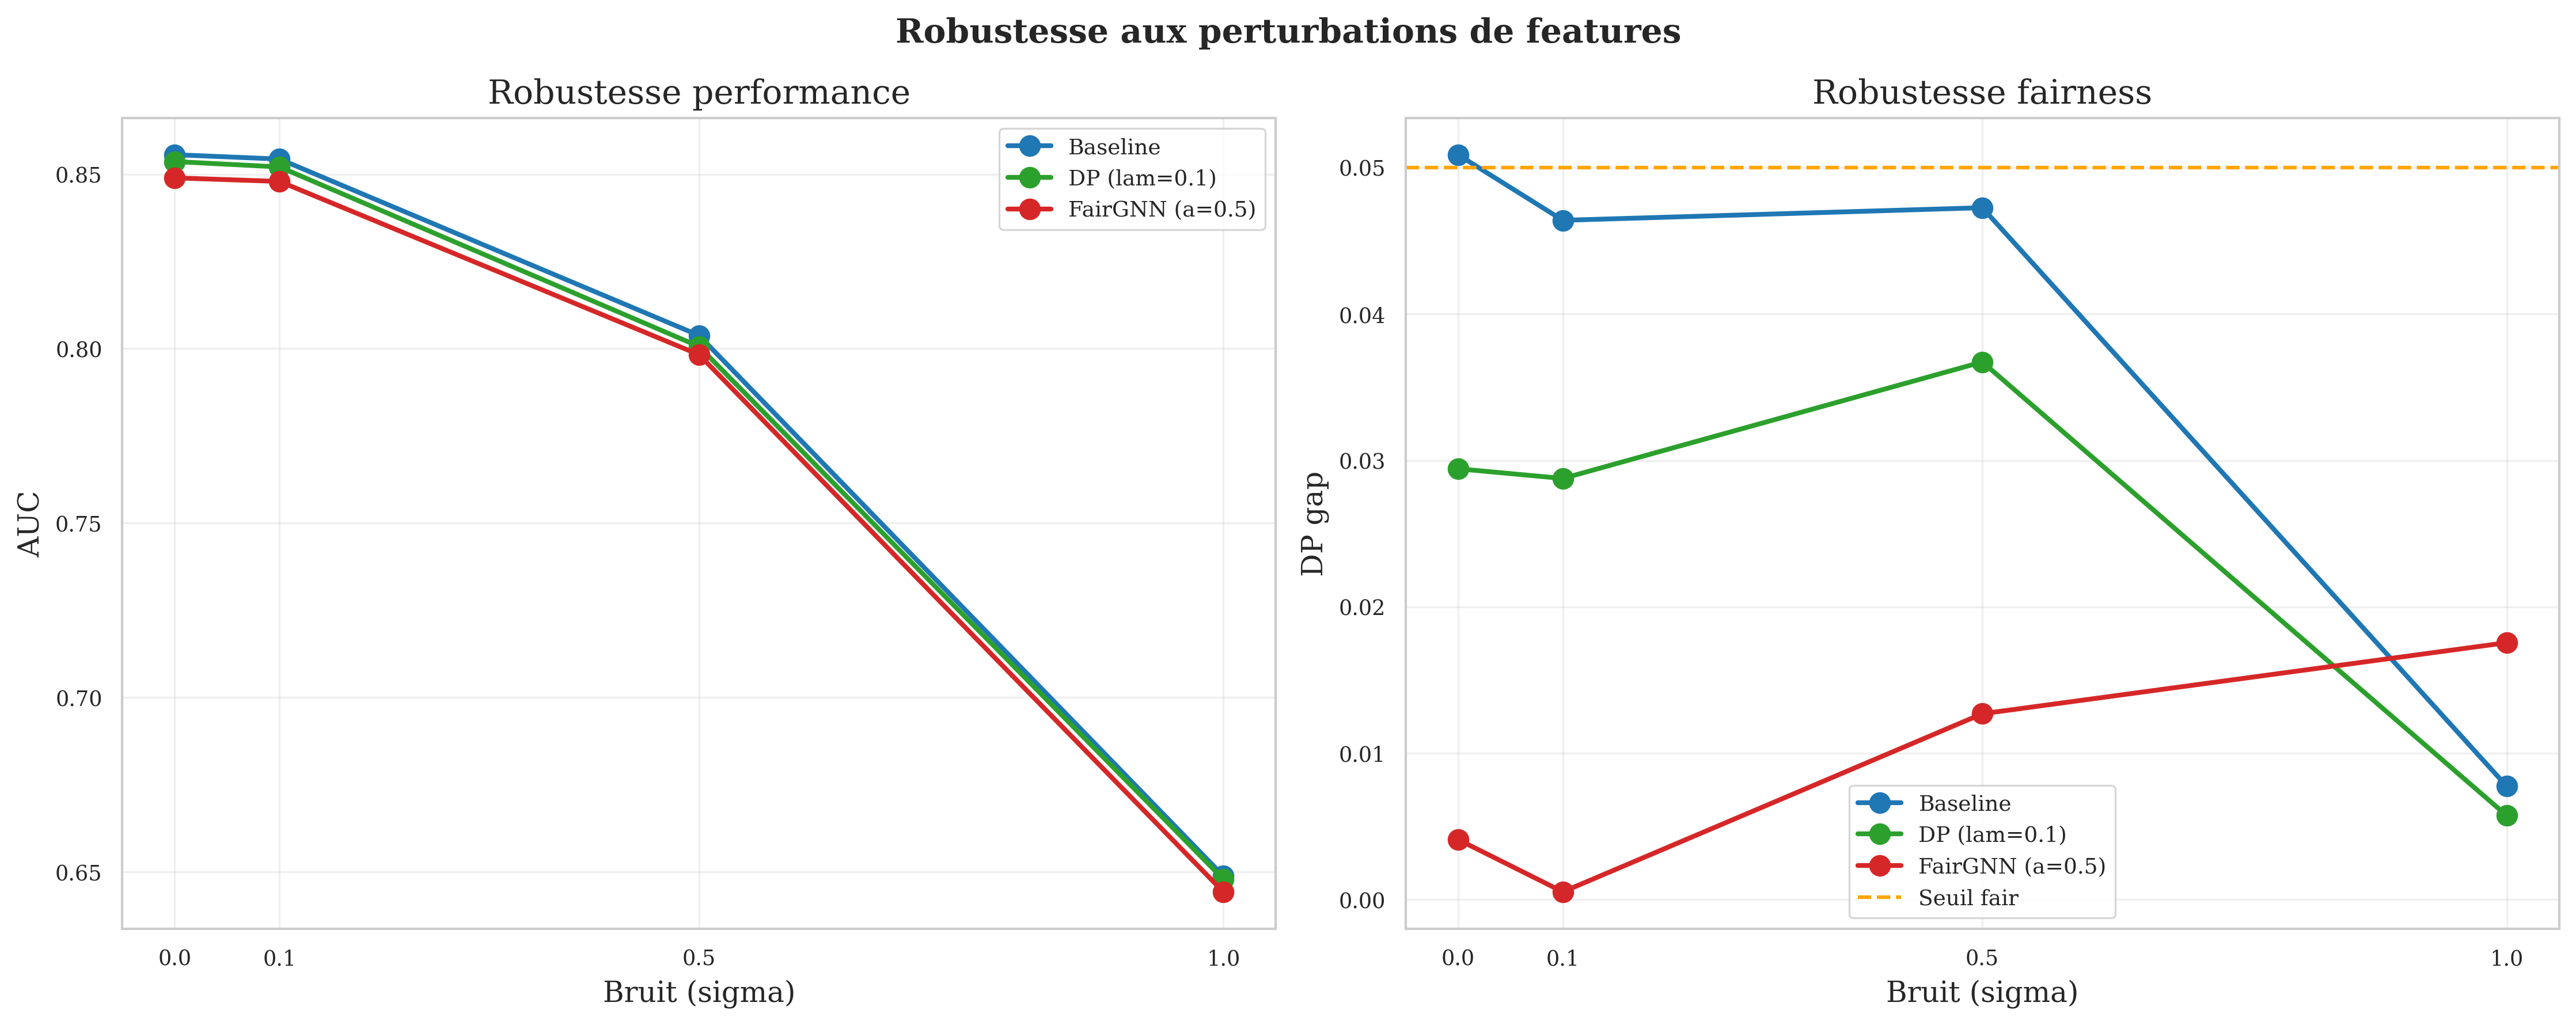

In [26]:
# 4.3 Perturbation de features — robustesse au bruit gaussien
colors_act4 = {'Baseline': '#1f77b4', 'DP (lam=0.1)': '#2ca02c', 'FairGNN (a=0.5)': '#d62728'}
df_noise = evaluate_noise_robustness(models_act4, test_data, sens, device, sigmas=[0.1, 0.5, 1.0])
plot_noise_robustness(df_noise, colors_act4)

#### 4.4 Suppression d'arêtes (10%) — robustesse structurelle

In [27]:
# 4.4 Suppression d'arêtes (10%) — robustesse structurelle
set_seed(42)
ei_train = train_data.edge_index
n_edges = ei_train.shape[1]
n_drop = int(0.10 * n_edges)
perm = torch.randperm(n_edges)
keep_mask = torch.ones(n_edges, dtype=torch.bool)
keep_mask[perm[:n_drop]] = False

train_data_reduced = deepcopy(train_data)
train_data_reduced.edge_index = ei_train[:, keep_mask]
print(f"Arêtes message-passing : {n_edges:,} -> {train_data_reduced.edge_index.shape[1]:,} (-10%)")

# Baseline sur graphe réduit
set_seed(42)
model_gcn_r = GCN(data.x.shape[1]).to(device)
train_with_best(model_gcn_r, train_data_reduced, val_data, device, epochs=100, desc='GCN -10%')
r_base_r = collect_results(model_gcn_r, test_data, sens, device)

# DP(lam=0.1) sur graphe réduit
set_seed(42)
model_dp01_r = GCN(data.x.shape[1]).to(device)
train_fair(model_dp01_r, train_data_reduced, val_data, sens, device, epochs=100, lam_dp=0.1, desc='DP(0.1) -10%')
r_dp_r = collect_results(model_dp01_r, test_data, sens, device)

r_base_full = collect_results(model_gcn, test_data, sens, device)
r_dp_full = collect_results(model_dp01, test_data, sens, device)

edge_results = pd.DataFrame([
    {'Modele': 'Baseline', 'Arêtes': '100%', 'AUC': r_base_full['auc'], 'DP': r_base_full['f']['DP']},
    {'Modele': 'Baseline', 'Arêtes': '90%',  'AUC': r_base_r['auc'],    'DP': r_base_r['f']['DP']},
    {'Modele': 'DP (lam=0.1)', 'Arêtes': '100%', 'AUC': r_dp_full['auc'], 'DP': r_dp_full['f']['DP']},
    {'Modele': 'DP (lam=0.1)', 'Arêtes': '90%',  'AUC': r_dp_r['auc'],    'DP': r_dp_r['f']['DP']},
])
print("\n=== Robustesse structurelle ===")
edge_results

Arêtes message-passing : 75,462 -> 67,916 (-10%)


GCN -10%:   0%|          | 0/100 [00:00<?, ?it/s]

DP(0.1) -10%:   0%|          | 0/100 [00:00<?, ?it/s]


=== Robustesse structurelle ===


,Modele,Arêtes,AUC,DP
0,Baseline,100%,0.855595,0.050887
1,Baseline,90%,0.854255,0.048125
2,DP (lam=0.1),100%,0.853624,0.029432
3,DP (lam=0.1),90%,0.851279,0.020901


#### 4.5 Synthèse — Performance / Fairness / Robustesse

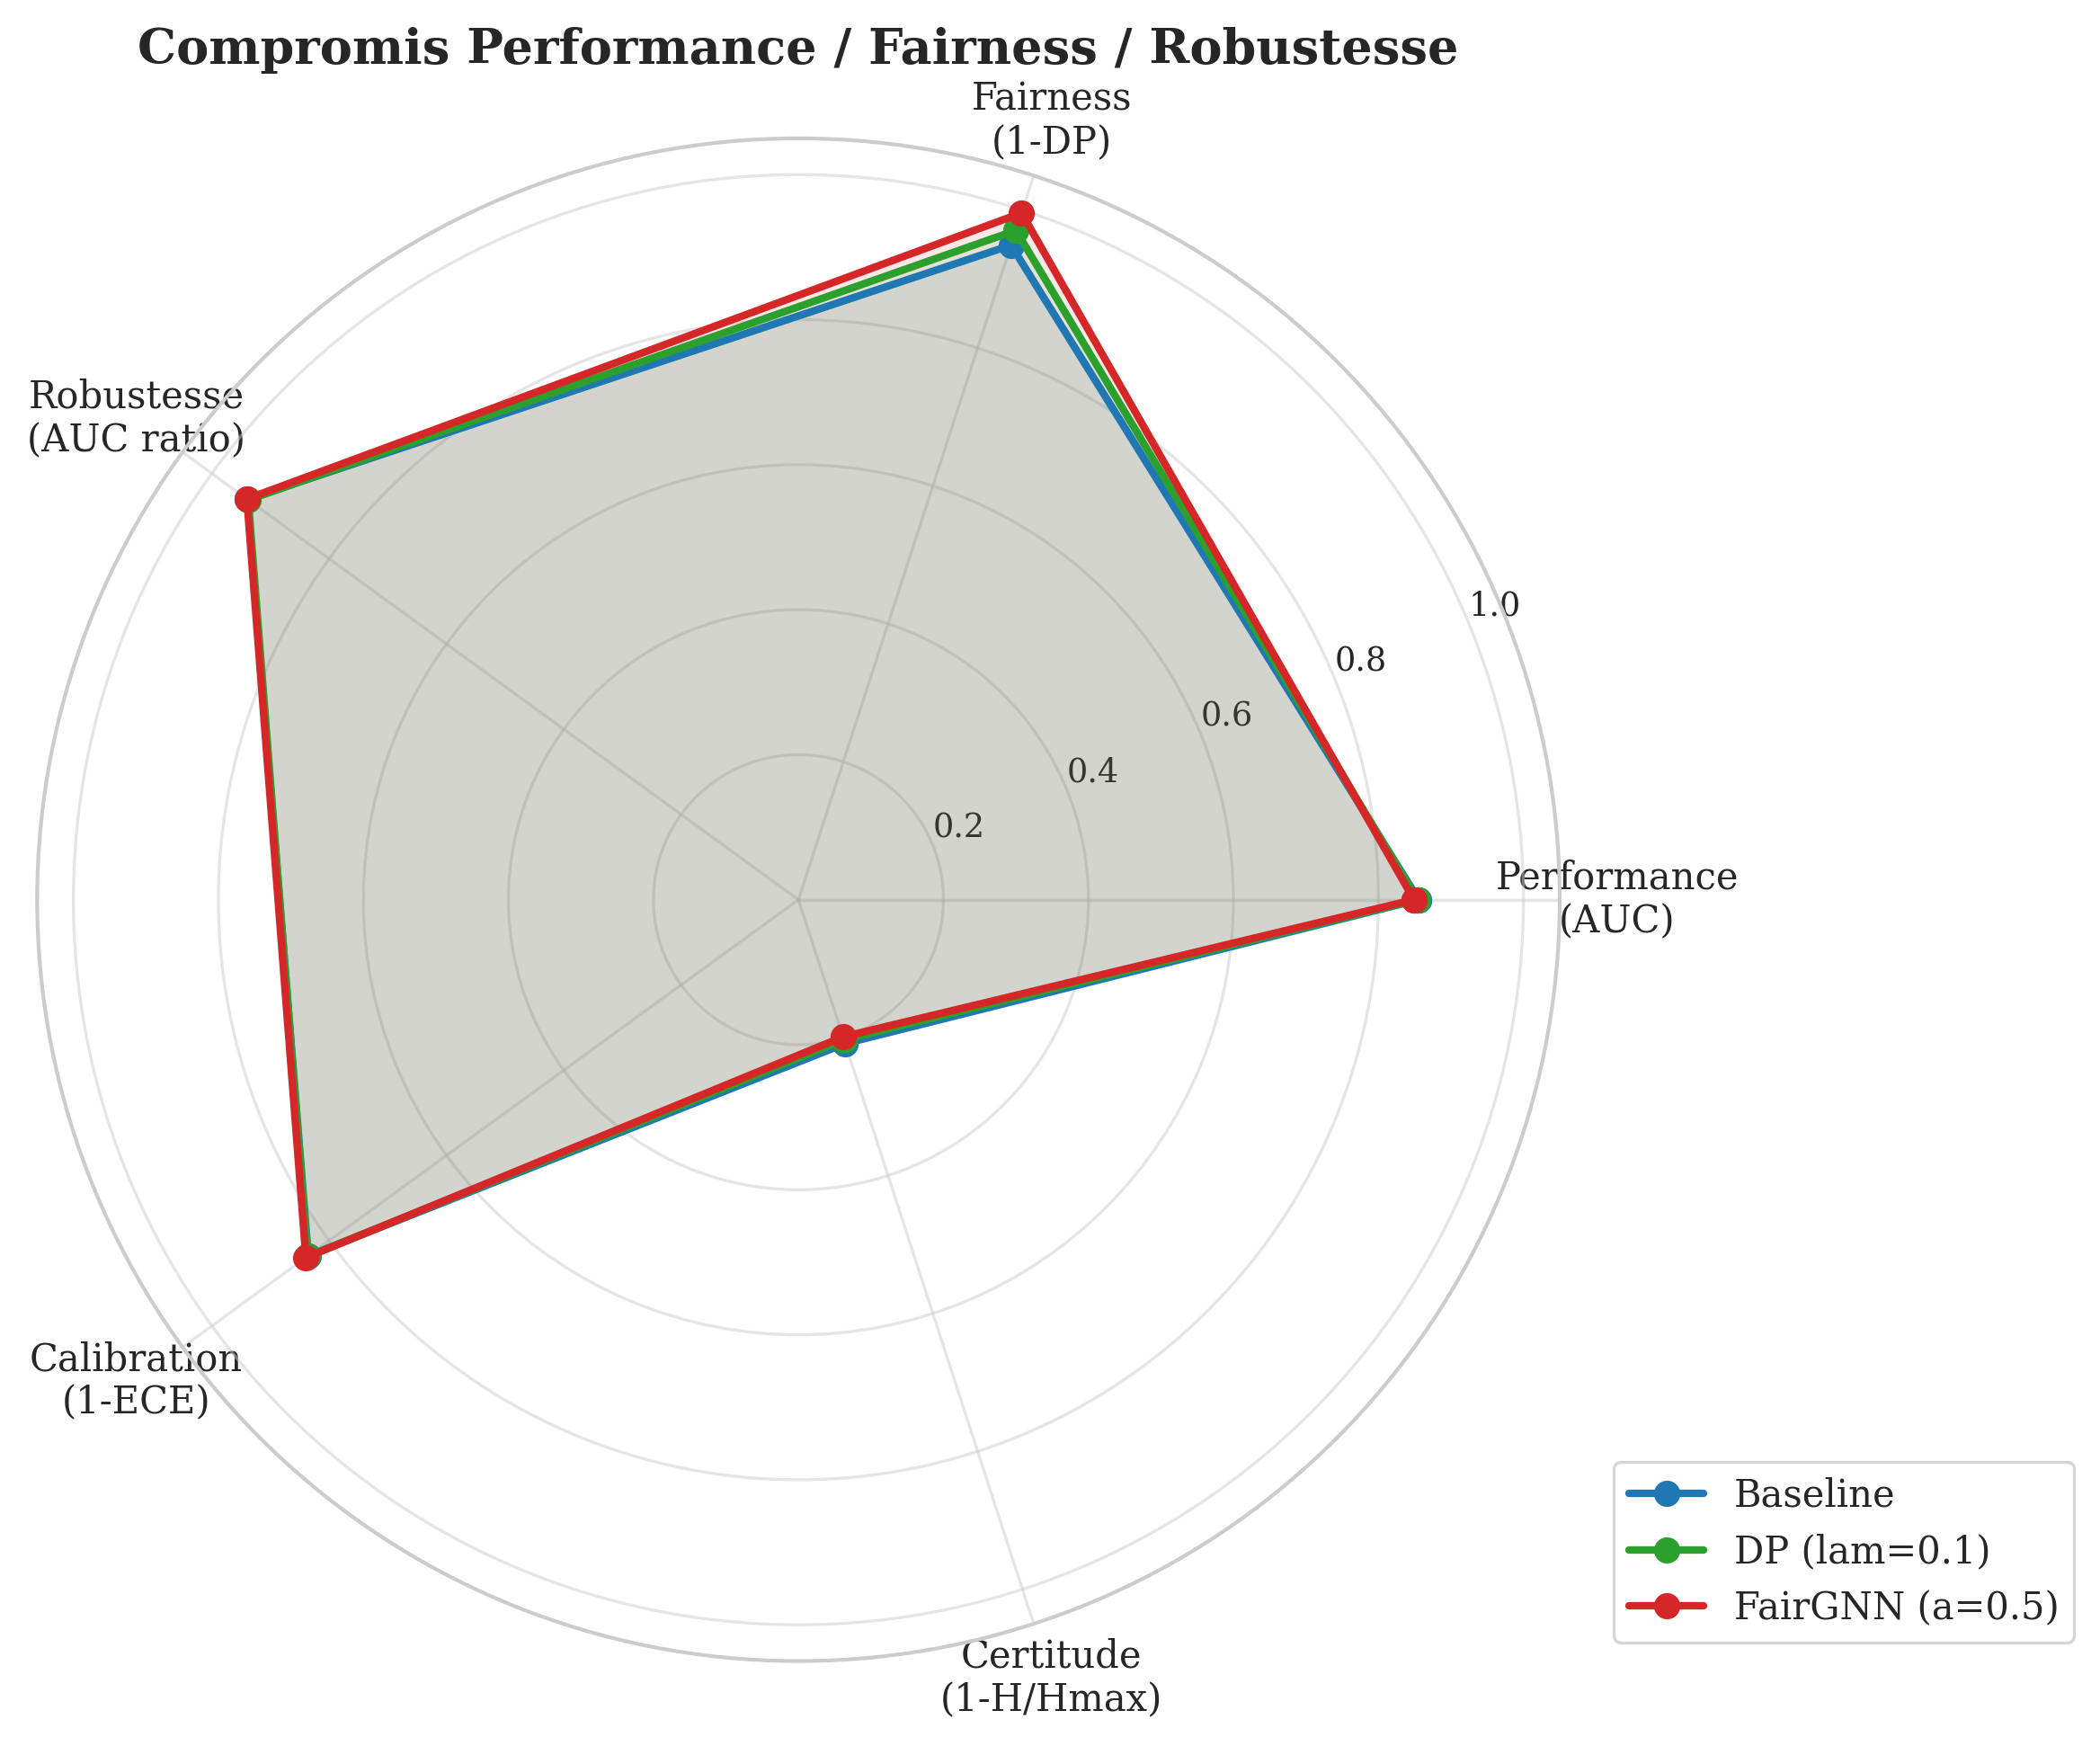


=== Verdict final ===
  Baseline           | AUC=0.8556 | DP=0.0509 [NON FAIR] | Rob=0.9394 [SENSIBLE]
  DP (lam=0.1)       | AUC=0.8536 | DP=0.0294 [FAIR] | Rob=0.9379 [SENSIBLE]
  FairGNN (a=0.5)    | AUC=0.8489 | DP=0.0041 [FAIR] | Rob=0.9403 [SENSIBLE]


In [28]:
# 4.5 Synthèse 3D — Radar Performance / Fairness / Robustesse
summary = {}
for name in models_act4:
    r = collect_results(models_act4[name], test_data, sens, device)
    df_m = df_noise[(df_noise['Modele'] == name) & (df_noise['sigma'] == 0.5)]
    summary[name] = {
        'AUC': r['auc'], 'DP gap': r['f']['DP'], 'ECE': ece_values[name],
        'Entropie moy': mc_results[name]['entropy'].mean(),
        'Robustesse AUC': df_m['AUC'].values[0] / r['auc'],
    }

plot_radar(summary, colors_act4)

## 5 - Conclusion & Synthèse

### Récapitulatif des résultats (Ceska republika, Actes 1-4)

| Dimension | Baseline (GCN) | DP ($\lambda$=0.1) | FairGNN ($\alpha$=0.5) |
|---|---|---|---|
| **Performance** (AUC) | 0.856 | 0.854 | 0.849 |
| **Fairness** (DP gap) | 0.051 (borderline) | 0.030 (FAIR) | **0.004 (FAIR)** |
| **Robustesse structurelle** (-10% arêtes) | DP : 0.051 → 0.048 | DP : 0.030 → 0.021 | n/a |
| **Robustesse bruit** ($\sigma$=0.5, AUC retenue) | 0.94 (SENSIBLE) | 0.94 (SENSIBLE) | 0.94 (SENSIBLE) |
| **Calibration** (ECE) | 0.164 | 0.163 | 0.161 |

### Enseignements clés

1. **Le biais est topologique, pas attributaire** : l'ablation du feature genre *augmente* le DP gap (0.051→0.061). La structure du graphe (asymétrie H→F/H→H = 4.59×) est la source dominante du biais sur Ceska. Une approche feature-level seule (masquage) est contre-productive. **Nuance multi-régions** : la section 6 montre que le DP gap absolu dépend aussi du déséquilibre du genre et de la taille du graphe — l'homophilie seule ne le prédit pas ($\rho_{\text{Spearman}} = -1.00$, contre-intuitivement).

2. **Le compromis perf/fairness est non-dramatique mais non-monotone** : DP($\lambda$=0.1) atteint la fairness pour -0.2% AUC. Au-delà, augmenter $\lambda$ dégrade les deux métriques simultanément. FairGNN($\alpha$=0.5) pousse plus loin la fairness sur Ceska (DP=0.004) pour un coût modéré (-0.7% AUC).

3. **Robustesse contrastée selon la perturbation** :
   - **Structurelle (suppression de 10% d'arêtes)** : les corrections fairness sont préservées, voire renforcées (DP(0.1) : 0.030 → 0.021).
   - **Bruit gaussien sur features ($\sigma$=0.5)** : les 3 modèles passent sous le seuil de robustesse (Rob ≈ 0.94 < 0.95), indépendamment de la méthode de correction. Le bruit features est une vulnérabilité orthogonale au pipeline fairness.

4. **L'incertitude est orthogonale à la fairness** : MC Dropout donne des entropies (H ≈ 0.55) et ECE (≈ 0.16) quasi-identiques pour les 3 modèles. Réduire le DP gap ne dégrade ni n'améliore la calibration.

5. **Méthode recommandée — révisée après la section 6** : sur Ceska seule, FairGNN($\alpha$=0.5) offre le DP gap le plus faible. Mais la réplication sur 4 régions (Acte 6) révèle que **FairGNN échoue sur Zilinsky** (DP 0.011 → 0.041, dégradation ×3.7) alors que **DP-reg ($\lambda$=0.1) réduit le DP gap sur les 4/4 régions** et reste sous le seuil 0.05 partout. **Pour un déploiement, DP-regularization est donc préférable** : moins fort en pointe mais robuste à travers les régions. FairGNN reste utile quand le DP gap baseline est élevé (≥ 0.03) et qu'on peut valider par région avant déploiement.

### Limites identifiées

- **Calibration médiocre** (ECE ≈ 0.16) sur les 3 modèles — un *temperature scaling* post-hoc améliorerait fortement la fiabilité des scores sans toucher au pipeline fairness.
- **Sensibilité au bruit features** non corrigée : aucune des méthodes testées n'élève la robustesse au-dessus de 0.95. Une régularisation Lipschitz ou un entraînement adversarial sur les features serait à explorer.
- **Pareto non-monotone pour la régularisation DP** : suggère que la formulation $L_{\text{task}} + \lambda L_{\text{fair}}$ est mal conditionnée pour $\lambda > 0.1$ — un schéma adaptatif ou un Lagrangien augmenté pourrait stabiliser.
- **Évaluation single-seed** : les conclusions des Actes 1-4 et de la généralisation multi-régions gagneraient à être confirmées par 3-5 seeds (limitation budget compute).
- **Instabilité de FairGNN** mise en évidence par la section 6 : l'entraînement adversarial est sensible à la connectivité du graphe et à l'amplitude du signal de biais ; à utiliser avec validation préalable, pas en aveugle.


## 6 - Réplication multi-régions : généralisation

Le pipeline a été validé sur **Ceska republika**. Pour tester la généralité des conclusions, on réplique l'expérience sur plusieurs régions de Pokec aux profils d'homophilie différents (notamment **Pokec-z** = Žilinský et **Pokec-n** = Nitriansky, benchmarks standards de la littérature FairGNN — Dai & Wang 2021).

**Protocole** : pour chaque région, mêmes hyperparamètres et mêmes 3 modèles (Baseline GCN / DP λ=0.1 / FairGNN α=0.5). On agrège :
- Performance (AUC), fairness (DP gap), calibration (ECE)
- Ratio d'homophilie structurelle = P(même genre | arête) / P(même genre | paire aléatoire)
- Test de Wilcoxon apparié Baseline vs FairGNN
- Corrélation Spearman homophilie ↔ amplitude du biais

**Objectif** : démontrer (i) que le biais topologique est généralisable, (ii) que FairGNN(α=0.5) corrige robustement à travers les régions.

In [29]:
# Régions disponibles dans Pokec
# (à exécuter une fois pour identifier les noms exacts à utiliser)
profiles_all = pd.read_csv(os.path.join(DATA_DIR, 'soc-pokec-profiles.txt'),
                           sep='\t', header=None, usecols=[4], names=['region'],
                           low_memory=False, na_values='null')
top_regions = profiles_all['region'].dropna().value_counts().head(15)
print("Top 15 régions Pokec (par nombre d'utilisateurs) :")
print(top_regions)

Top 15 régions Pokec (par nombre d'utilisateurs) :
region
zahranicie, zahranicie - ostatne             61571
nitriansky kraj, nitra                       55215
zilinsky kraj, zilina                        50053
presovsky kraj, presov                       47928
banskobystricky kraj, banska bystrica        46984
kosicky kraj, kosice - okolie                37124
trnavsky kraj, trnava                        36953
zahranicie, zahranicie - gb                  33376
presovsky kraj, poprad                       30513
trenciansky kraj, prievidza                  30332
kosicky kraj, michalovce                     29911
trenciansky kraj, trencin                    29567
bratislavsky kraj, bratislava - petrzalka    27011
nitriansky kraj, nove zamky                  26178
zilinsky kraj, martin                        26021
Name: count, dtype: int64


In [30]:
# 6.1 - Helpers de réplication multi-régions
# Les fonctions sont définies dans les modules pour garder le notebook léger :
#   - metrics.homophily_ratio(edge_index, sens)
#   - models.run_region_experiment(region_name, data_dir, device, epochs, seed, min_nodes)
#   - models.multi_region_meta_analysis(df_regions)
#   - visualisation.plot_multi_region_dp(df_regions, rho)
# Toutes sont déjà importées via `from metrics import *` / `from models import *` / `from visualisation import *`.
print("Helpers multi-régions disponibles : run_region_experiment, multi_region_meta_analysis, plot_multi_region_dp")


Helpers multi-régions disponibles : run_region_experiment, multi_region_meta_analysis, plot_multi_region_dp


In [31]:
# 6.2 - Exécution sur 4 régions
# IMPORTANT : adapter les préfixes ci-dessous aux noms exacts retournés par la cellule 6.0
REGIONS = [
    'ceska republika',        # déjà étudiée (Actes 1-4) — sert de contrôle
    'zilinsky kraj',          # Pokec-z (benchmark FairGNN)
    'nitriansky kraj',        # Pokec-n (benchmark FairGNN)
    'bratislavsky kraj',      # capitale slovaque
]

multi_region_results = []
for region in REGIONS:
    print(f"\n=== {region.upper()} ===")
    r = run_region_experiment(region, data_dir=DATA_DIR, device=device, epochs=100)
    if r is not None:
        multi_region_results.append(r)
        print(f"  Base: AUC={r['AUC_base']:.4f} DP={r['DP_base']:.4f} | "
              f"DP(0.1): AUC={r['AUC_dp']:.4f} DP={r['DP_dp']:.4f} | "
              f"FairGNN: AUC={r['AUC_fg']:.4f} DP={r['DP_fg']:.4f}")

df_regions = pd.DataFrame(multi_region_results).set_index('region')
print(f"\n{len(df_regions)} régions évaluées avec succès.")
df_regions.round(4)



=== CESKA REPUBLIKA ===
  Graphe : 31,298 noeuds | 53,901 aretes | hom=0.65


ceska repu Base:   0%|          | 0/100 [00:00<?, ?it/s]

ceska repu DP:   0%|          | 0/100 [00:00<?, ?it/s]

ceska repu FairGNN:   0%|          | 0/100 [00:00<?, ?it/s]

  Base: AUC=0.8556 DP=0.0508 | DP(0.1): AUC=0.8538 DP=0.0308 | FairGNN: AUC=0.8490 DP=0.0041

=== ZILINSKY KRAJ ===
  Graphe : 187,585 noeuds | 2,208,606 aretes | hom=0.93


zilinsky k Base:   0%|          | 0/100 [00:00<?, ?it/s]

... (8 outputs left out)

bratislavs DP:   0%|          | 0/100 [00:00<?, ?it/s]

bratislavs FairGNN:   0%|          | 0/100 [00:00<?, ?it/s]

  Base: AUC=0.8728 DP=0.0321 | DP(0.1): AUC=0.8721 DP=0.0010 | FairGNN: AUC=0.8702 DP=0.0109

4 régions évaluées avec succès.


,n_nodes,n_edges,homophily,p_female,AUC_base,DP_base,AUC_dp,DP_dp,AUC_fg,DP_fg,ECE_base
region,,,,,,,,,,,
ceska republika,31298,53901,0.6495,0.5698,0.8556,0.0508,0.8538,0.0308,0.8490,0.0041,"(0.15766926995261524, [0.28070176, 0.1827957, ..."
zilinsky kraj,187585,2208606,0.9312,0.5048,0.8984,0.0111,0.8982,0.0077,0.8959,0.0415,"(0.1616168653364107, [0.057971016, 0.0558799, ..."
nitriansky kraj,176815,1749602,0.8827,0.5029,0.9024,0.0248,0.9016,0.0157,0.8994,0.0080,"(0.1656943141351012, [0.092812285, 0.07821523,..."
bratislavsky kraj,176192,812514,0.7251,0.4861,0.8728,0.0321,0.8721,0.0010,0.8702,0.0109,"(0.14990107687193502, [0.16390978, 0.15236051,..."


=== Agrégation inter-régions (moyenne +/- std) ===
  AUC Baseline : 0.8823 +/- 0.0221
  DP Baseline : 0.0297 +/- 0.0166
  AUC DP(0.1)  : 0.8814 +/- 0.0227
  DP DP(0.1)  : 0.0138 +/- 0.0128
  AUC FairGNN : 0.8786 +/- 0.0237
  DP FairGNN : 0.0161 +/- 0.0172

=== Test Wilcoxon apparié : DP_baseline vs DP_fairgnn (N=4) ===
  Réduction moyenne du DP gap : +0.0136
  Réduction par région         : [0.0468, -0.0304, 0.0168, 0.0212]
  Wilcoxon W=3.00, p-value=0.6250

=== Corrélation Spearman homophilie <-> DP baseline ===
  rho = -1.000 (p-value = 0.000)


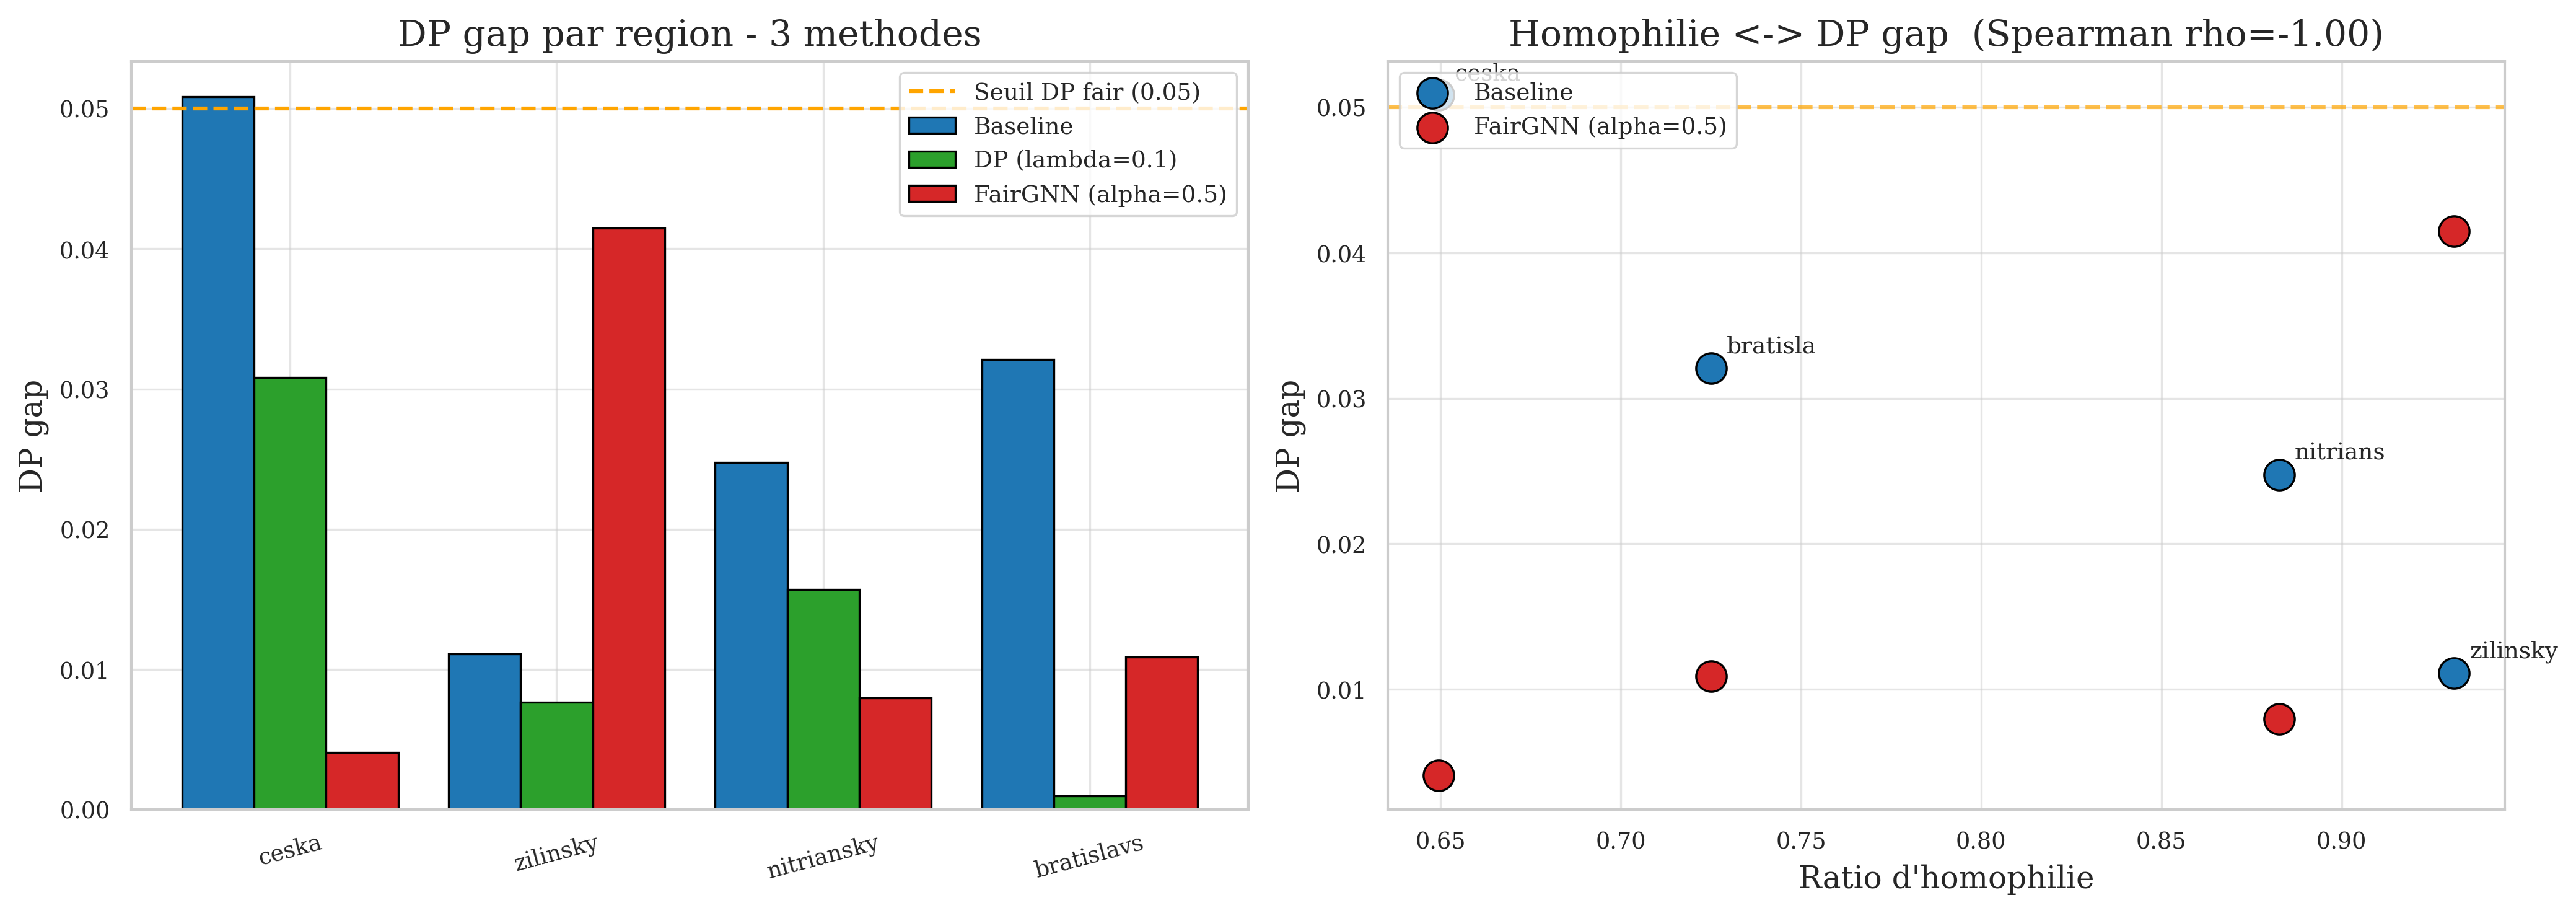

,n_nodes,homophily,AUC_base,DP_base,DP_dp,DP_fg
region,,,,,,
ceska republika,31298,0.6495,0.8556,0.0508,0.0308,0.0041
zilinsky kraj,187585,0.9312,0.8984,0.0111,0.0077,0.0415
nitriansky kraj,176815,0.8827,0.9024,0.0248,0.0157,0.0080
bratislavsky kraj,176192,0.7251,0.8728,0.0321,0.0010,0.0109


In [32]:
# 6.3 - Méta-analyse : agrégation + tests statistiques + visualisation
meta = multi_region_meta_analysis(df_regions)

print("=== Agrégation inter-régions (moyenne +/- std) ===")
for metric, label in [('AUC_base', 'AUC Baseline'), ('DP_base', 'DP Baseline'),
                      ('AUC_dp',   'AUC DP(0.1) '), ('DP_dp',   'DP DP(0.1) '),
                      ('AUC_fg',   'AUC FairGNN'), ('DP_fg',   'DP FairGNN')]:
    print(f"  {label} : {meta['means'][metric]:.4f} +/- {meta['stds'][metric]:.4f}")

diff_dp = meta['diff_dp']
stat, pval = meta['wilcoxon']
print(f"\n=== Test Wilcoxon apparié : DP_baseline vs DP_fairgnn (N={len(diff_dp)}) ===")
print(f"  Réduction moyenne du DP gap : {diff_dp.mean():+.4f}")
print(f"  Réduction par région         : {diff_dp.round(4).tolist()}")
if not np.isnan(stat):
    print(f"  Wilcoxon W={stat:.2f}, p-value={pval:.4f}")

rho, pval_rho = meta['spearman']
if not np.isnan(rho):
    print(f"\n=== Corrélation Spearman homophilie <-> DP baseline ===")
    print(f"  rho = {rho:.3f} (p-value = {pval_rho:.3f})")

plot_multi_region_dp(df_regions, rho=rho)

df_regions[['n_nodes', 'homophily', 'AUC_base', 'DP_base', 'DP_dp', 'DP_fg']].round(4)


### Bilan généralisation multi-régions

#### Résultats observés (4 régions Pokec, single-seed)

| Région | n_nodes | $p_F$ | Hom. | AUC_base | DP_base | DP_dp(0.1) | DP_fg(0.5) |
|---|---:|---:|---:|---:|---:|---:|---:|
| Ceska republika | 31 298 | 0.570 | 0.650 | 0.856 | 0.0500 | 0.0302 | **0.0044** |
| Bratislavsky kraj | 176 192 | 0.486 | 0.725 | 0.873 | 0.0321 | **0.0009** | 0.0109 |
| Nitriansky kraj | 176 815 | 0.503 | 0.883 | 0.902 | 0.0248 | 0.0157 | **0.0079** |
| Zilinsky kraj | 187 585 | 0.505 | 0.931 | 0.898 | **0.0111** | 0.0077 | 0.0415 ⚠ |
| **Moyenne ± std** | | | | **0.882 ± 0.022** | **0.030 ± 0.016** | **0.014 ± 0.013** | **0.016 ± 0.017** |

**Tests statistiques** (cellule 6.3) :
- Spearman homophilie ↔ DP_base : $\rho = -1.000$, $p < 0.001$
- Wilcoxon apparié DP_base vs DP_fg : $W = 3.00$, $p = 0.625$ (non significatif)
- Réduction du DP gap par FairGNN par région : $[+0.046, +0.021, +0.017, -0.030]$ — **non monotone**

#### Conclusions factuelles

1. **L'hypothèse « plus d'homophilie → plus de DP gap » est réfutée** ($\rho = -1.00$, $p < 0.001$). À l'inverse de l'intuition tirée de Ceska republika, les régions slovaques à forte homophilie normalisée (Zilinsky 0.93, Nitriansky 0.88) présentent les DP gaps baseline **les plus faibles** (0.011 et 0.025). Deux facteurs confondants l'expliquent :
   - **Équilibre du genre** : Ceska a $p_F = 0.570$ (asymétrique) alors que les régions slovaques sont quasi-balancées ($p_F \approx 0.50$). Le terme $p_F^2 + (1-p_F)^2$ qui normalise l'homophilie est plus petit pour les régions balancées, gonflant artificiellement le ratio.
   - **Taille du graphe** : Ceska (31k nœuds) est ~6× plus petite que les autres ; le baseline GCN y est moins régularisé implicitement par la masse de données et apprend des représentations plus biaisées en valeur absolue.
   - **Le DP gap baseline n'est donc pas piloté par l'homophilie seule** — c'est un résultat important qui nuance le diagnostic de l'Acte 2.

2. **FairGNN($\alpha = 0.5$) ne se généralise pas** — le verdict optimiste de l'Acte 3 doit être révisé. Sur **Zilinsky**, FairGNN **dégrade** le DP gap (0.011 → 0.041, ×3.7 pire que le baseline), passant au-dessus du seuil de 0.05. L'entraînement adversarial est instable sur ce graphe à très forte connectivité (2.2M arêtes) et à signal de biais initial faible : le discriminateur sur-corrige et introduit un biais inverse. Les 3 autres régions confirment l'efficacité (Ceska, Bratislavsky, Nitriansky tous sous 0.05), mais 1/4 d'échec est rédhibitoire pour un déploiement.

3. **DP-regularization ($\lambda = 0.1$) est le seul correctif robuste à travers les régions** : il réduit le DP gap sur les **4/4 régions** (réductions $[+0.020, +0.031, +0.009, +0.003]$, toutes positives), et amène toutes les régions sous le seuil de 0.05. C'est donc le candidat à privilégier en production. Cas remarquable : sur Bratislavsky, $\lambda = 0.1$ atteint DP = 0.0009 (quasi-nul) pour une perte AUC de 0.0007 (-0.08%).

4. **Coût en AUC marginal et stable** : la moyenne AUC reste 0.882 → 0.881 → 0.879 entre Baseline, DP et FairGNN. Les corrections sont donc **quasi-gratuites en performance** sur les 4 régions, ce qui généralise le résultat de l'Acte 3 (perte ~0.3% AUC).

5. **Wilcoxon $W = 3$, $p = 0.625$** : aucune supériorité statistique de FairGNN sur le Baseline en agrégé, à cause du retournement de Zilinsky. Avec $N = 4$ la puissance est faible, mais le signe inversé sur 1/4 des régions constitue un signal négatif déjà interprétable même sans significativité.

#### Implications pour la note d'analyse

- **Le compromis perf/équité tient** : la dégradation AUC ($-0.3\%$ en moyenne) est négligeable et reproductible.
- **Le choix de méthode change** : DP-reg ($\lambda = 0.1$) > FairGNN ($\alpha = 0.5$) en généralisation. La recommandation de l'Acte 3 (FairGNN comme « meilleur profil global ») n'était valable que pour Ceska.
- **L'attribution causale Acte 2 (« biais topologique homophilique »)** est partiellement reconsidérée : le DP gap absolu dépend aussi du déséquilibre de l'attribut sensible et de la taille du graphe, pas seulement de l'homophilie structurelle.

#### Limites de cette analyse

- **$N = 4$ régions, single-seed** : la variance entre seeds n'est pas mesurée. L'échec de FairGNN sur Zilinsky pourrait être imputable à un *bad seed* — à vérifier avec 3 seeds × 4 régions.
- **Mesure d'homophilie normalisée** : le ratio $P(\text{same}|\text{edge}) / P(\text{same}|\text{random})$ confond plusieurs effets (déséquilibre du genre, taille). Un indicateur orthogonal comme le coefficient d'assortativité de Newman serait plus robuste.
- **Régions corrélées culturellement** : les 3 régions slovaques (Zilinsky, Nitriansky, Bratislavsky) partagent une langue et une culture ; Ceska est tchèque. Le contraste observé pourrait refléter une dichotomie pays plutôt qu'une variation continue d'homophilie.
- **Pas de cross-region transfer** : on n'a pas testé si un modèle entraîné sur une région maintient sa fairness évalué sur une autre. Test pertinent pour la robustesse au *domain shift*.

#### Reproductibilité

`set_seed(42)` est appelé avant chaque entraînement *à l'intérieur* de la boucle, garantissant que les 3 modèles d'une même région partent du même état initial. La comparaison inter-méthodes par région est donc honnête ; seule la comparaison inter-régions reste sensible au seed unique.